# Patrones invisibles: información, incertidumbre y movilidad urbana

**Consultoría analítica para UrbanMove** · NYC Taxi Trip Duration (1.458.644 viajes, enero–junio 2016)
Aprendizaje de Máquina No Supervisado · Universidad de La Sabana · 2026-II

> "Tenemos más de un millón de viajes históricos y no sabemos qué hacer con ellos más allá de mirar promedios. Necesitamos entender qué tan predecible es la demanda en cada zona y momento del día, qué perfiles de viaje existen realmente, y dónde debemos posicionar conductores para minimizar tiempos de espera sin sobre-ofertar en zonas de baja demanda. Todo hallazgo debe estar cuantificado."
>
> Dirección de Operaciones, UrbanMove

## La pregunta que hay que responder

UrbanMove no necesita un mapa de colores: necesita saber **cuánta incertidumbre real hay en la demanda**, **qué tan distintos son los patrones entre momentos del día** y **qué decisión operativa concreta** se deriva de cada hallazgo.

## Cómo está organizado el cuaderno

| Sección | Pregunta | Responsable |
|---|---|---|
| 1. Datos y variables derivadas | ¿Con qué estamos trabajando? | Equipo |
| 2. Exploración univariada | ¿Qué esconde el promedio? | Equipo |
| 3. Calidad y base de trabajo | ¿Qué datos entran al análisis y por qué? | Rol 4 |
| 4. Incertidumbre e información | ¿Qué tan predecible es la demanda? | Rol 1 |
| 5. Segmentación por partición | ¿Dónde están los polos de demanda? | Rol 2 |
| 6. Mezclas y variables latentes | ¿Qué perfiles de viaje existen? | Rol 3 |
| 7. Decisiones para UrbanMove | ¿Qué hacer mañana por la mañana? | Rol 4 |

Cada sección arranca con la pregunta que responde y cierra con la lectura de los números obtenidos.

In [1]:
# Dependencias del proyecto. Se ejecuta una sola vez por entorno.
!pip install -q pandas numpy scipy scikit-learn geopandas pyproj geopy holidays matplotlib seaborn


In [2]:
# --- Librerías ---
import numpy as np
import pandas as pd
import geopandas as gpd
import holidays
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

import pyproj
from geopy.distance import geodesic
from shapely.geometry import Point

from sklearn.cluster import DBSCAN, KMeans, kmeans_plusplus
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# --- Configuración global ---
SEED = 2026                    # semilla única para muestreo, K-means, DBSCAN y EM
SAMPLE_SIZE = 50_000           # tamaño de muestra para los bloques con costo O(n²)
SLA_SPEED_KMH = 10.0           # umbral de congestión usado en las recomendaciones
LAPLACE_ALPHA = 0.5            # suavizado, solo para KL: q no puede tener ceros
EMPIRICAL_ALPHA = 0.0          # entropias e informacion mutua: estimador de frecuencias

BLUE, LIGHT_BLUE, ORANGE = "#2a78d6", "#9ec5f4", "#eb6834"
INK, SOFT_INK, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "font.size": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": SOFT_INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": SOFT_INK, "ytick.color": SOFT_INK,
})
sns.set_theme(style="whitegrid", rc=plt.rcParams)

# Separador de miles en formato local (1.458.644)
thousands = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

def fmt(x, dec=0):
    """Formatea un número con separador de miles local."""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## 1. Datos y variables derivadas

Se carga el archivo `train.csv` completo. A las variables originales se les agregan cinco derivadas que son las que después sostienen todo el análisis:

- **`trip_distance`**: distancia geodésica entre recogida y destino. No se usa distancia euclidiana sobre lat/lon porque la Tierra no es plana.
- **`pickup_neighborhood` / `pickup_borough`** (y sus equivalentes de destino): barrio y distrito oficiales de NYC, obtenidos con un *spatial join* contra el shapefile de zonas de taxi.
- **`hour`, `time_of_day`, `day_name`, `is_weekend`, `is_holiday`**: contexto temporal de cada viaje, construido desde `pickup_datetime`. Los festivos salen del calendario oficial de EE. UU.

In [3]:
df = pd.read_csv("nyc-taxi-trip-duration/train.csv")

df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  object 
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  object 
 3   dropoff_datetime    1458644 non-null  object 
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  object 
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 122.4+ MB


In [5]:
df.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
std,4.987772e-01,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03
min,1.000000e+00,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06


In [6]:
df.shape

(1458644, 11)

# Creación Variables Auxiliares

In [7]:
# Distancia geodesica sobre el elipsoide WGS84, vectorizada con pyproj.Geod.
# Es la MISMA geodesica de Karney que resuelve geopy.distance.geodesic, pero resuelta
# sobre arreglos completos en lugar de fila por fila: 1,46 millones de llamadas en
# Python tardaban minutos y volvian el cuaderno practicamente no re-ejecutable.
# Abajo se verifica contra geopy sobre una muestra aleatoria para dejar constancia de
# que no es una aproximacion (haversine si lo seria): es el mismo numero.
geod = pyproj.Geod(ellps="WGS84")
_, _, distance_m = geod.inv(df["pickup_longitude"].to_numpy(), df["pickup_latitude"].to_numpy(),
                            df["dropoff_longitude"].to_numpy(), df["dropoff_latitude"].to_numpy())
df["trip_distance"] = distance_m / 1000.0

# Control de equivalencia contra la implementacion de referencia.
_check = df.sample(2000, random_state=SEED)
_ref = np.array([geodesic((a, b), (c, d)).km for a, b, c, d in zip(
    _check["pickup_latitude"], _check["pickup_longitude"],
    _check["dropoff_latitude"], _check["dropoff_longitude"])])
display(pd.DataFrame([{
    "viajes contrastados": len(_check),
    "diferencia maxima [km]": f"{np.abs(_check['trip_distance'].to_numpy() - _ref).max():.3e}",
    "implementacion de referencia": "geopy.distance.geodesic (WGS84)",
}]))


,viajes contrastados,diferencia maxima [km],implementacion de referencia
0,2000,2.121e-12,geopy.distance.geodesic (WGS84)


In [8]:
gdf_zones = gpd.read_file("taxi_zones/taxi_zones.shp")
gdf_zones = gdf_zones.to_crs(epsg=4326)

display(pd.DataFrame([{"zonas en el shapefile": len(gdf_zones),
                       "sistema de referencia": str(gdf_zones.crs),
                       "distritos": gdf_zones["borough"].nunique()}]))

,zonas en el shapefile,sistema de referencia,distritos
0,263,EPSG:4326,6


In [9]:
def get_spatial_neighbors(df_input, lat_col, lon_col, prefix="pickup"):
    # Crear geometría de puntos a partir de las coordenadas
    geometry = [
        Point(xy) for xy in zip(df_input[lon_col], df_input[lat_col])
    ]
    gdf_points = gpd.GeoDataFrame(df_input, geometry=geometry, crs="EPSG:4326")

    # Realizar el Spatial Join con el mapa de barrios
    cross = gpd.sjoin(gdf_points, gdf_zones, how="left", predicate="within")

    # 'zone' representa el barrio (ej. Times Square, Harlem) y 'borough' el distrito (ej. Manhattan, Brooklyn)
    return cross["zone"], cross["borough"]

# AGREGAR BARRIOS DE ORIGEN (PICKUP) Y DESTINO (DROPOFF)
df["pickup_neighborhood"], df["pickup_borough"] = get_spatial_neighbors(
    df, "pickup_latitude", "pickup_longitude"
)

df["dropoff_neighborhood"], df["dropoff_borough"] = get_spatial_neighbors(
    df, "dropoff_latitude", "dropoff_longitude"
)

In [10]:
df["trip_duration_minutes"] = df["trip_duration"] / 60

df["datetime"] = pd.to_datetime(df["pickup_datetime"])
groups = [-1, 5, 11, 18, 24]
labels = ["Late Night", "Morning", "Afternoon", "Evening"]

df["hour"] = df["datetime"].dt.hour
df["time_of_day"] = pd.cut(df["hour"], bins=groups, labels=labels)

df["day_name"] = df["datetime"].dt.day_name()
df["is_weekend"] = df["datetime"].dt.dayofweek >= 5


us_holidays = holidays.US(years=df["datetime"].dt.year.unique())
df["is_holiday"] = df["datetime"].dt.date.isin(us_holidays)

df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,...,pickup_borough,dropoff_neighborhood,dropoff_borough,trip_duration_minutes,datetime,hour,time_of_day,day_name,is_weekend,is_holiday
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,...,Manhattan,Upper East Side South,Manhattan,7.583333,2016-03-14 17:24:55,17,Afternoon,Monday,False,False
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,...,Manhattan,Greenwich Village South,Manhattan,11.050000,2016-06-12 00:43:35,0,Late Night,Sunday,True,False
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,...,Manhattan,Seaport,Manhattan,35.400000,2016-01-19 11:35:24,11,Morning,Tuesday,False,False
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,...,Manhattan,Financial District South,Manhattan,7.150000,2016-04-06 19:32:31,19,Evening,Wednesday,False,False
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,...,Manhattan,Upper West Side South,Manhattan,7.250000,2016-03-26 13:30:55,13,Afternoon,Saturday,True,False


## 2. Exploración univariada: qué esconde el promedio

Las distribuciones de este dataset tienen colas extremas: la duración llega a 58.771 minutos (más de 40 días) y la velocidad a 9.274 km/h. Graficadas con el rango completo, todas las barras se aplastan contra el eje y no se ve nada.

Criterios de estas gráficas:

- **Eje recortado al percentil 99** y la cola declarada por escrito al pie, en lugar de esconderla.
- **Franja de percentiles** (p5, cuartiles, mediana) en vez de diagrama de caja: muestra la misma posición y dispersión sin los bigotes de Tukey, que aquí no aportan nada.
- **Barras horizontales ordenadas** para las categóricas: los nombres de los barrios no caben en el eje x (248 aparecen en el archivo completo; 237 quedan en la base de trabajo tras los filtros de calidad).
- **Una sola paleta**: azul para la serie, naranja solo para el valor que se quiere resaltar.

In [11]:
# --- Utilidades de análisis y graficación ---

def elbow_index(series):
    """Codo de una curva: el punto más alejado de la recta que une sus extremos.

    Se usa dos veces en el cuaderno, sobre curvas distintas: la del BIC para elegir
    el número de componentes de la mezcla (Rol 3) y la de distancia al vecino
    min_samples para elegir eps en DBSCAN (Rol 2). Devuelve la etiqueta del índice,
    no la posición.
    """
    x = series.index.to_numpy(dtype=float)
    y = series.to_numpy(dtype=float)
    x_norm = (x - x[0]) / (x[-1] - x[0])
    y_norm = (y - y.min()) / (y.max() - y.min())
    distance = np.abs((y_norm[-1] - y_norm[0]) * x_norm - (x_norm[-1] - x_norm[0]) * y_norm
                      + x_norm[-1] * y_norm[0] - y_norm[-1] * x_norm[0])
    return int(x[np.argmax(distance / np.hypot(y_norm[-1] - y_norm[0], x_norm[-1] - x_norm[0]))])


# Las distribuciones del dataset tienen colas extremas (duración hasta 58.771 min),
# así que los ejes se recortan a un percentil y la cola se reporta como texto al pie.

def numeric_summary(series):
    """Estadísticos que acompañan cada distribución."""
    return {
        "n": series.notna().sum(), "mean": series.mean(), "median": series.median(),
        "skew": series.skew(), "max": series.max(),
    }

def percentile_strip(ax, series, color=BLUE):
    """Resumen de posición: rango p5–p95, caja intercuartil y mediana.

    Sustituye a boxplot() porque aquí no se necesitan los bigotes de Tukey.
    """
    p5, q1, med, q3, p95 = np.percentile(series, [5, 25, 50, 75, 95])
    ax.hlines(0, p5, p95, color=color, lw=2)
    ax.add_patch(plt.Rectangle((q1, -0.25), q3 - q1, 0.5, facecolor=LIGHT_BLUE, edgecolor=color))
    ax.vlines(med, -0.32, 0.32, color=ORANGE, lw=2.5)
    for value, label in [(p5, "p5"), (med, "mediana"), (p95, "p95")]:
        ax.annotate(f"{label}\n{fmt(value, 1)}", xy=(value, -0.45), ha="center", va="top",
                    fontsize=8, color=SOFT_INK)
    ax.set_ylim(-0.9, 0.6)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)

def plot_numeric(series, title, unit="", clip=0.99):
    """Histograma recortado al percentil `clip` más una franja de percentiles."""
    series = series.dropna()
    stats = numeric_summary(series)
    upper = series.quantile(clip)
    tail = int((series > upper).sum())
    body = series[series <= upper]

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.1), gridspec_kw={"width_ratios": [3, 2]})
    axes[0].hist(body, bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
    axes[0].axvline(stats["median"], color=ORANGE, lw=2)
    axes[0].annotate(f"mediana {fmt(stats['median'], 1)}", xy=(stats["median"], 0.93),
                     xycoords=("data", "axes fraction"), xytext=(6, 0), textcoords="offset points",
                     color=ORANGE, fontsize=8.5, weight="bold")
    axes[0].set_title(f"{title} · hasta el percentil {clip:.0%}")
    axes[0].set_xlabel(unit or title)
    axes[0].set_ylabel("viajes")
    axes[0].yaxis.set_major_formatter(thousands)

    percentile_strip(axes[1], body)
    axes[1].set_xlabel(unit or title)
    axes[1].set_title("Posición y dispersión")

    footer = (f"n = {fmt(stats['n'])}  ·  media {fmt(stats['mean'], 2)}  ·  "
              f"asimetría {stats['skew']:.1f}  ·  máximo {fmt(stats['max'], 1)}  ·  "
              f"fuera del eje: {fmt(tail)} viajes ({tail / len(series):.2%})")
    fig.text(0, -0.04, footer, fontsize=8.5, color=SOFT_INK)
    plt.tight_layout()
    plt.show()

def plot_categorical(series, title, top=None, order=None):
    """Barras horizontales ordenadas con la participación de cada categoría."""
    counts = series.value_counts(dropna=False)
    if order is not None:
        counts = counts.reindex([c for c in order if c in counts.index])
    total = counts.sum()
    note = ""
    if top and len(counts) > top:
        rest = counts.iloc[top:].sum()
        note = f"Se muestran {top} de {len(counts)} categorías; el resto suma {rest / total:.1%}."
        counts = counts.iloc[:top]
    counts = counts.iloc[::-1]

    fig, ax = plt.subplots(figsize=(9, max(2.2, 0.34 * len(counts) + 1)))
    ax.barh([str(i) for i in counts.index], counts.values, color=BLUE, height=0.68)
    for y, value in enumerate(counts.values):
        ax.text(value + total * 0.004, y, f"{value / total:.1%}", va="center",
                fontsize=8.5, color=SOFT_INK)
    ax.set_title(title)
    ax.set_xlabel("viajes")
    ax.xaxis.set_major_formatter(thousands)
    ax.set_xlim(0, counts.max() * 1.12)
    ax.grid(axis="y", visible=False)
    if note:
        fig.text(0, -0.02, note, fontsize=8.5, color=SOFT_INK)
    plt.tight_layout()
    plt.show()

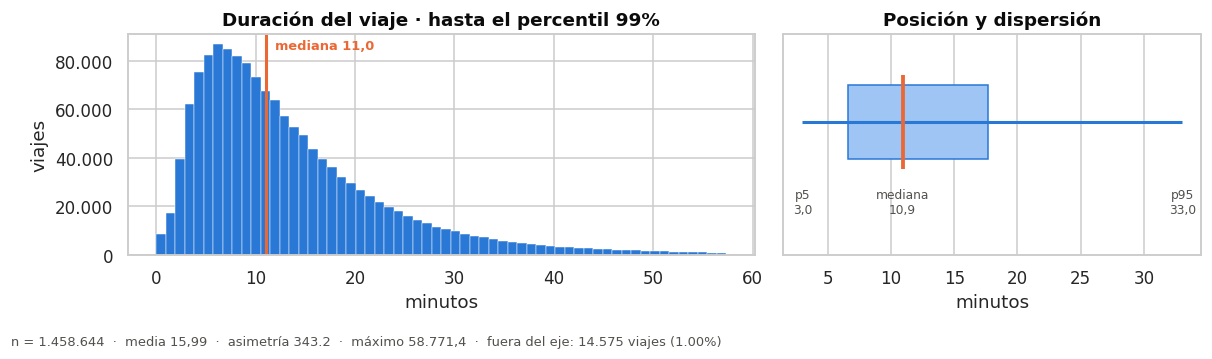

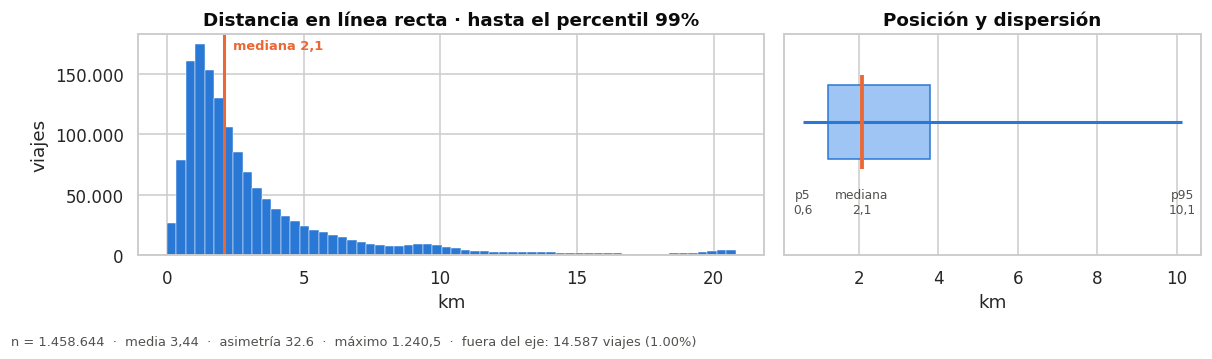

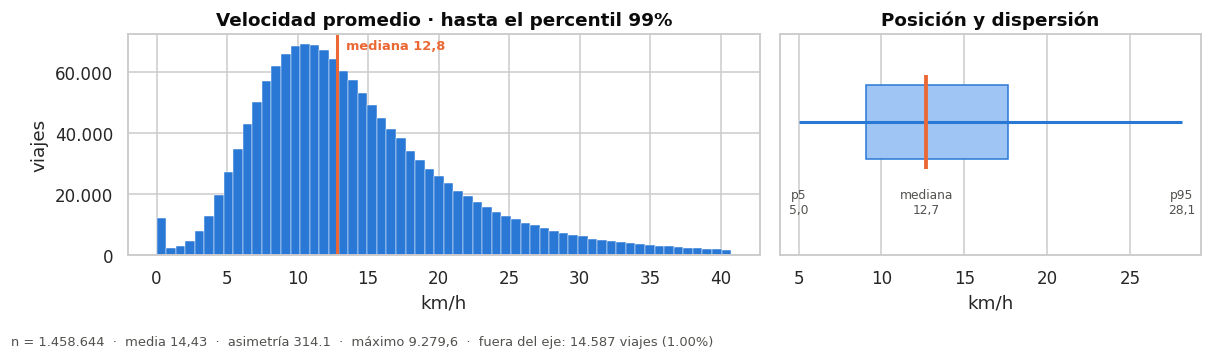

In [12]:
# Velocidad promedio: se deriva aquí porque es la variable que delata los registros corruptos.
df["speed_kmh"] = df["trip_distance"] / (df["trip_duration"] / 3600)

plot_numeric(df["trip_duration_minutes"], "Duración del viaje", "minutos")
plot_numeric(df["trip_distance"], "Distancia en línea recta", "km")
plot_numeric(df["speed_kmh"], "Velocidad promedio", "km/h")

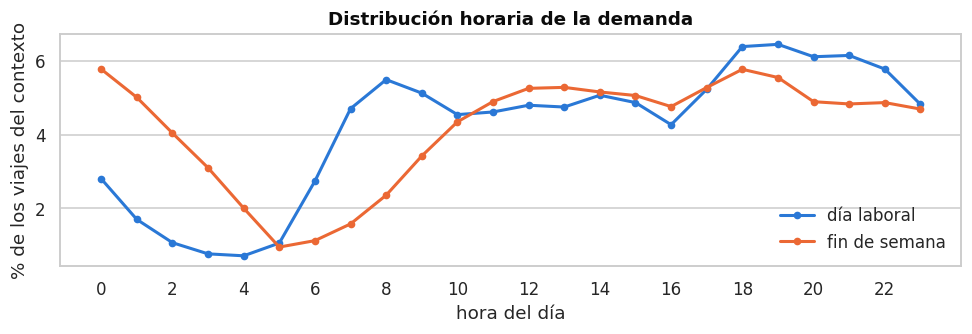

In [13]:
# Demanda por hora, separando día laboral de fin de semana: el patrón horario
# es distinto en cada contexto y el agregado los mezcla.
hourly = (df.groupby(["hour", "is_weekend"], observed=True).size()
          .unstack(fill_value=0).rename(columns={False: "laboral", True: "fin de semana"}))
hourly_share = 100 * hourly / hourly.sum()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(hourly_share.index, hourly_share["laboral"], color=BLUE, lw=2, marker="o", ms=4,
        label="día laboral")
ax.plot(hourly_share.index, hourly_share["fin de semana"], color=ORANGE, lw=2, marker="o", ms=4,
        label="fin de semana")
ax.set_title("Distribución horaria de la demanda")
ax.set_xlabel("hora del día")
ax.set_ylabel("% de los viajes del contexto")
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

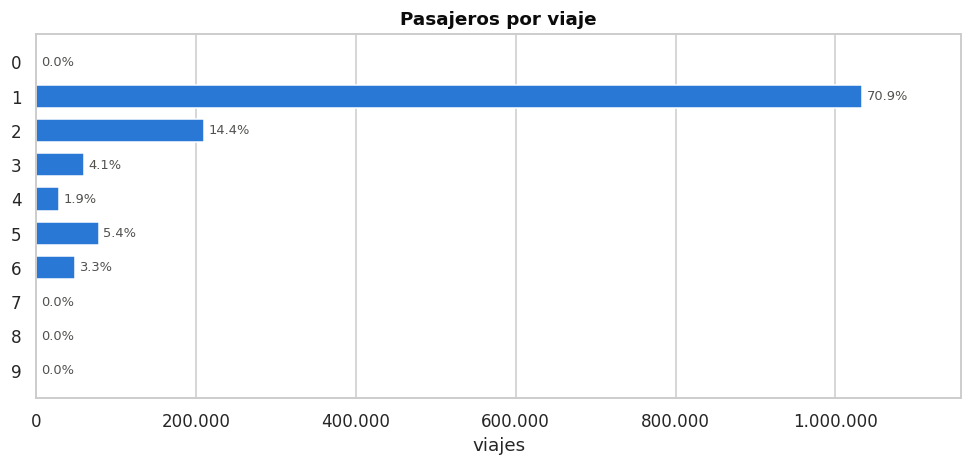

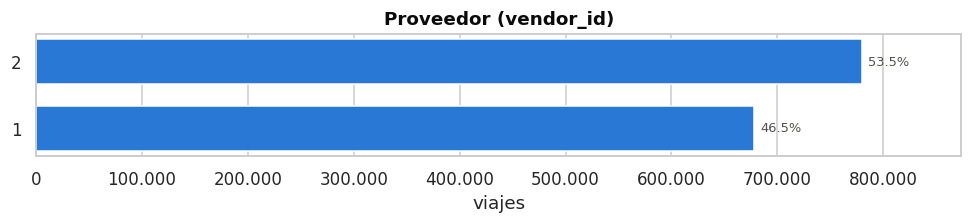

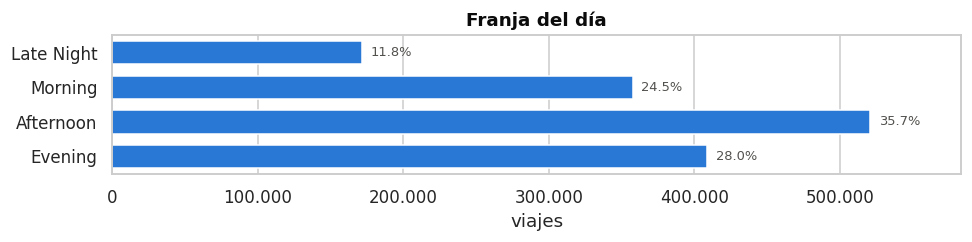

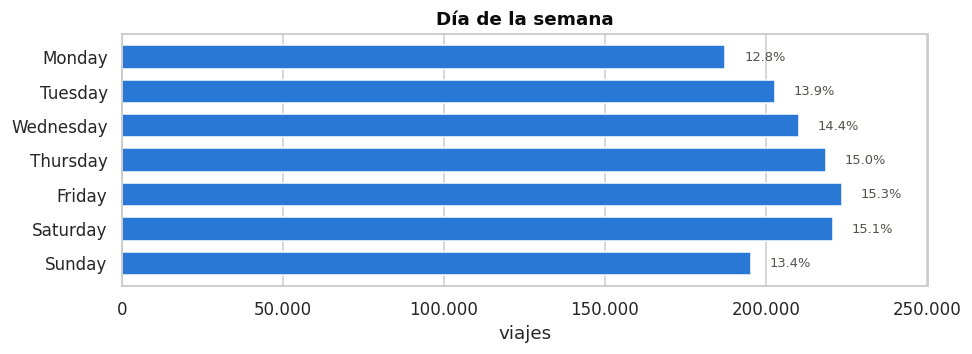

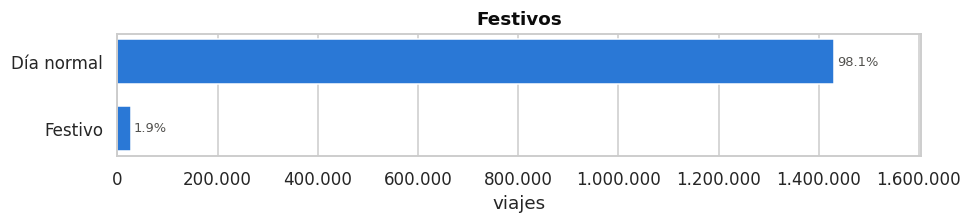

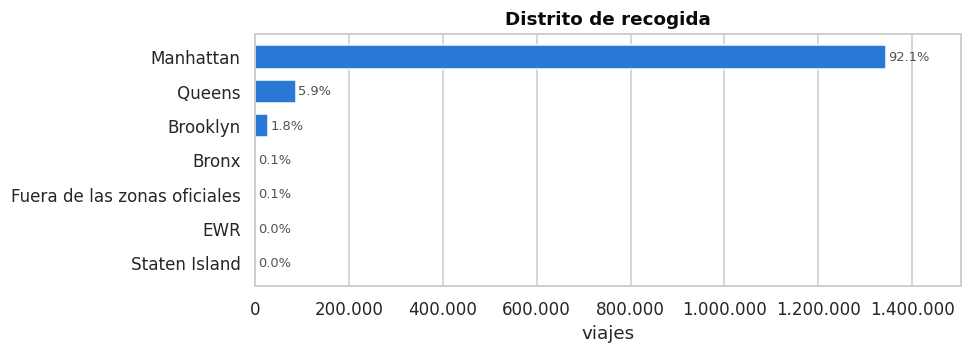

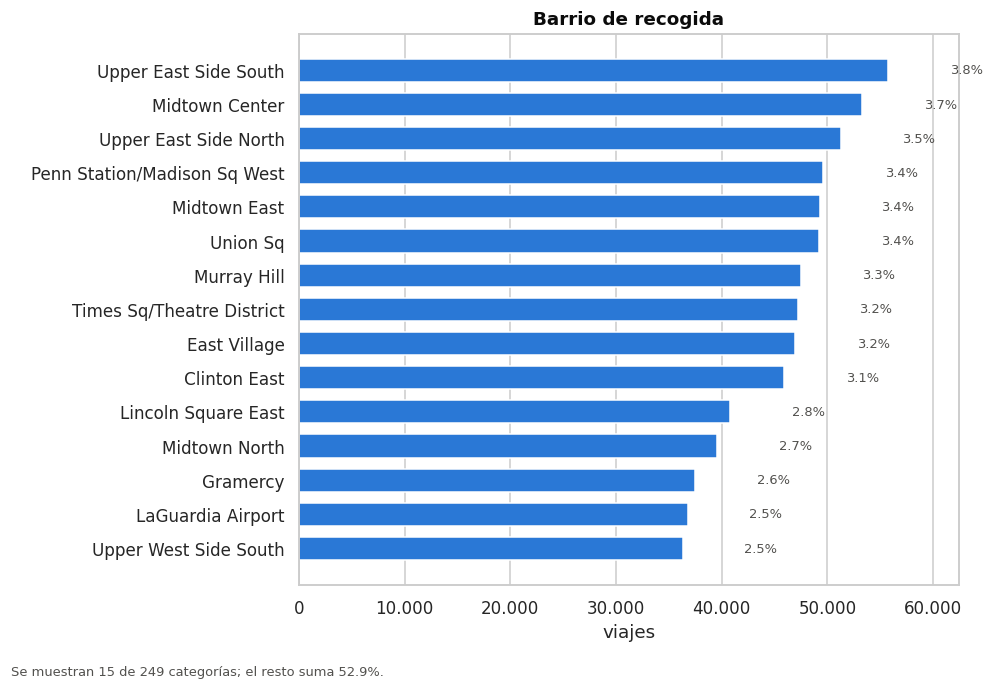

In [14]:
plot_categorical(df["passenger_count"].astype(str), "Pasajeros por viaje",
                 order=[str(i) for i in range(10)])
plot_categorical(df["vendor_id"].astype(str), "Proveedor (vendor_id)")
plot_categorical(df["time_of_day"].astype(str), "Franja del día",
                 order=["Late Night", "Morning", "Afternoon", "Evening"])
plot_categorical(df["day_name"], "Día de la semana",
                 order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
plot_categorical(df["is_holiday"].map({False: "Día normal", True: "Festivo"}), "Festivos")
plot_categorical(df["pickup_borough"].fillna("Fuera de las zonas oficiales"), "Distrito de recogida")
plot_categorical(df["pickup_neighborhood"].fillna("Fuera de las zonas oficiales"),
                 "Barrio de recogida", top=15)

### Lectura

- **Duración**: mediana de 11 minutos contra media de 16. Con asimetría de 343, la media describe la cola, no al viaje típico.
- **Distancia**: mediana de 2,1 km y un segundo montículo cerca de los 20 km: son los aeropuertos. La distribución no es unimodal, hay dos poblaciones mezcladas.
- **Velocidad**: mediana de 12,8 km/h. Es la variable que delata los registros corruptos, con máximos de 9.274 km/h.
- **Demanda horaria**: separar por `is_weekend` muestra dos curvas distintas que el agregado ocultaba. El día laboral tiene pico a las 8 y a las 18; el fin de semana arranca tarde, no cae en la madrugada y su pico es más plano.
- **Zona**: el 92 % de las recogidas es en Manhattan y 15 barrios concentran casi la mitad de los viajes. Esa cola larga es la que se mide en la sección 4.
- **Festivos**: 1,9 % de los viajes. Son pocos, así que cualquier conclusión sobre festivos va con menos respaldo estadístico.

## 3. Calidad y base de trabajo · Rol 4

**Estrategia de datos.** Las entropías, la información mutua y la divergencia KL se calculan sobre la **base de trabajo completa después de los filtros de calidad: 1.431.173 viajes**. Son tablas de frecuencias, el costo es bajo y no hay razón para muestrear: no se usa una muestra, pero tampoco el archivo crudo, porque los registros que se filtran distorsionan justamente las variables que se miden aquí.

Para clustering y mezclas se usa una **muestra aleatoria de 50.000 viajes con semilla 2026**: el índice de silueta es O(n²) y DBSCAN sobre 1,4 millones de puntos no cabe en memoria. Con ese tamaño, el error estándar de una proporción es menor a 0,25 puntos porcentuales.

**Filtros.** Se descartan los registros **implausibles o no informativos para este análisis**, no los viajes atípicos que resulten incómodos. La palabra no es *imposible*: un recorrido de menos de 200 m en línea recta puede ser una ida y vuelta real, y uno por debajo de 2 km/h puede ser un viaje con espera larga. Lo que ocurre es que ninguno informa sobre el patrón espacial ni sobre la velocidad de circulación, que es lo que se está midiendo. Cada regla se cuenta por separado para poder defenderla una por una.

In [15]:
# --- Reglas de calidad ---
# Cada regla aísla un tipo de registro implausible o no informativo. Se evalúan por separado
# para poder reportar cuánto pesa cada una antes de aplicarlas en conjunto.
quality_rules = {
    "Duración fuera de 1–120 min": ~df["trip_duration_minutes"].between(1, 120),
    "Distancia fuera de 0,2–60 km": ~df["trip_distance"].between(0.2, 60),
    "Velocidad fuera de 2–90 km/h": ~df["speed_kmh"].between(2, 90),
    "Pasajeros fuera de 1–6": ~df["passenger_count"].between(1, 6),
    "Recogida o destino fuera de las zonas oficiales":
        df["pickup_neighborhood"].isna() | df["dropoff_neighborhood"].isna(),
}

quality_report = pd.DataFrame({
    "regla": list(quality_rules),
    "viajes afectados": [int(mask.sum()) for mask in quality_rules.values()],
})
quality_report["% del total"] = (100 * quality_report["viajes afectados"] / len(df)).round(2)

invalid = np.zeros(len(df), dtype=bool)
for mask in quality_rules.values():
    invalid |= mask.to_numpy()

trips = df.loc[~invalid].copy()

quality_report.loc[len(quality_report)] = ["Total descartado (reglas combinadas)",
                                           int(invalid.sum()), round(100 * invalid.mean(), 2)]
quality_report.loc[len(quality_report)] = ["Base de trabajo", len(trips),
                                           round(100 * len(trips) / len(df), 2)]
display(quality_report)

,regla,viajes afectados,% del total
0,Duración fuera de 1–120 min,10848,0.74
1,"Distancia fuera de 0,2–60 km",16926,1.16
2,Velocidad fuera de 2–90 km/h,17298,1.19
3,Pasajeros fuera de 1–6,65,0.00
4,Recogida o destino fuera de las zonas oficiales,4003,0.27
5,Total descartado (reglas combinadas),27471,1.88
6,Base de trabajo,1431173,98.12


In [16]:
# Composición de la base de trabajo según las variables derivadas del pickup_datetime.
context_profile = pd.DataFrame({
    "viajes": [len(trips),
               int(trips["is_weekend"].sum()),
               int((~trips["is_weekend"]).sum()),
               int(trips["is_holiday"].sum())],
    "duración mediana (min)": [trips["trip_duration_minutes"].median(),
                               trips.loc[trips["is_weekend"], "trip_duration_minutes"].median(),
                               trips.loc[~trips["is_weekend"], "trip_duration_minutes"].median(),
                               trips.loc[trips["is_holiday"], "trip_duration_minutes"].median()],
    "velocidad mediana (km/h)": [trips["speed_kmh"].median(),
                                 trips.loc[trips["is_weekend"], "speed_kmh"].median(),
                                 trips.loc[~trips["is_weekend"], "speed_kmh"].median(),
                                 trips.loc[trips["is_holiday"], "speed_kmh"].median()],
}, index=["Base completa", "Fin de semana", "Día laboral", "Festivos"]).round(2)
display(context_profile)

,viajes,duración mediana (min),velocidad mediana (km/h)
Base completa,1431173,11.07,12.88
Fin de semana,408144,10.37,14.29
Día laboral,1023029,11.38,12.32
Festivos,26708,9.31,15.70


### Lectura

Se descarta el **1,88 %** de los registros y quedan 1.431.173 viajes. Ninguna regla elimina más del 1,2 %, así que la base no cambia de naturaleza: es limpieza, no recorte.

La composición por contexto ya adelanta algo: el fin de semana la velocidad mediana sube de 12,3 a 14,3 km/h y en festivos llega a 15,7. La ciudad se mueve más rápido cuando la gente no trabaja, y eso reaparece en los perfiles del Rol 3.

## 4. Incertidumbre e información · Rol 1

**Bloque temático:** probabilidad, entropía de Shannon, entropía cruzada, divergencia KL, información mutua, entropía condicional, desigualdad de Jensen y log-sum-exp.

**Pregunta:** ¿qué tan predecible es la demanda, y qué variable aporta información real sobre dónde estará el próximo viaje?

Todo se mide en **bits**, lo que permite traducir cada resultado a una cantidad interpretable: si H = 5,7 bits, la demanda se comporta como si estuviera repartida por igual entre 2^5,7 ≈ 53 zonas.

In [17]:
# --- Teoría de la información ---
# Todo se calcula en bits (log base 2): H en bits permite leer 2**H como el número
# de categorías equivalentes si la demanda estuviera repartida por igual.

def to_probabilities(counts, alpha=LAPLACE_ALPHA):
    """Distribucion con suavizado de Laplace. Se usa SOLO para la divergencia KL,
    donde un cero en q daria infinito. Las entropias y la informacion mutua usan el
    estimador empirico sin suavizar (EMPIRICAL_ALPHA = 0)."""
    values = np.asarray(counts, dtype=float) + alpha
    return values / values.sum()

def entropy(p):
    """H(p) = -Σ p log2 p"""
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def cross_entropy(p, q):
    """H(p, q) = -Σ p log2 q"""
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    support = p > 0
    return float(-(p[support] * np.log2(q[support])).sum())

def kl_divergence(p, q):
    """D_KL(p||q) = H(p, q) - H(p)"""
    return cross_entropy(p, q) - entropy(p)

def information_from_joint(table, alpha=EMPIRICAL_ALPHA):
    """Todas las cantidades de informacion derivadas de UNA sola tabla conjunta.

    Se construye la conjunta una sola vez y de ahi salen las marginales, las entropias,
    la condicional y la informacion mutua, de modo que las identidades
    I(X;Y) = H(Y) - H(Y|X) = H(X) + H(Y) - H(X,Y) se cumplen de forma exacta.
    Suavizar cada marginal por separado las rompe por un residuo pequeno.

    Por defecto alpha = 0: para H, H(.|.) e I se usa el estimador empirico de
    frecuencias, que es lo que corresponde cuando hay 1,4 millones de observaciones y
    ninguna celda vacia hace falta rellenar (0 log 0 = 0 esta bien definido). El
    suavizado de Laplace se reserva para la divergencia KL, donde un cero en q daria
    infinito. Mezclar los dos criterios inflaba H(zona) y con ella la informacion mutua.
    """
    joint = np.asarray(table, dtype=float) + alpha
    joint = joint / joint.sum()
    p_x, p_y = joint.sum(axis=1), joint.sum(axis=0)
    h_x, h_y, h_joint = entropy(p_x), entropy(p_y), entropy(joint.ravel())
    return {"H(X)": h_x, "H(Y)": h_y, "H(X,Y)": h_joint,
            "H(Y|X)": h_joint - h_x, "H(X|Y)": h_joint - h_y,
            "I(X;Y)": h_x + h_y - h_joint,
            "p_x": p_x, "p_y": p_y, "joint": joint}

def mutual_information(x, y, alpha=EMPIRICAL_ALPHA):
    """I(X;Y) y H(Y), derivados de la conjunta empirica construida una sola vez."""
    info = information_from_joint(pd.crosstab(x, y).to_numpy(), alpha)
    return info["I(X;Y)"], info["H(Y)"]

def log_sum_exp(values):
    """log Σ exp(x) con el máximo factorizado para evitar underflow/overflow."""
    values = np.asarray(values, dtype=float)
    peak = values.max()
    return float(peak + np.log(np.exp(values - peak).sum()))

### 4.1 · Cuánta incertidumbre hay en la zona de recogida

In [18]:
# Entropia de la zona de recogida, global y condicionada a la hora.
# Todo sale de UNA sola tabla conjunta (hora x zona) empirica, sin suavizar: las
# marginales, la condicional y la informacion mutua se derivan de ella, de modo que
# I(hora;zona) = H(zona) - H(zona|hora) se cumple exacto y no por aproximacion.
hour_zone = pd.crosstab(trips["hour"], trips["pickup_neighborhood"])
n_zones = hour_zone.shape[1]
max_entropy = np.log2(n_zones)

info_hour_zone = information_from_joint(hour_zone.to_numpy())
zone_entropy = info_hour_zone["H(Y)"]
conditional_entropy = info_hour_zone["H(Y|X)"]
mi_hour_zone = info_hour_zone["I(X;Y)"]

# Curva por hora: cada fila de la conjunta, renormalizada.
row_probs = info_hour_zone["joint"] / info_hour_zone["joint"].sum(axis=1, keepdims=True)
hourly_entropy = pd.DataFrame({
    "viajes": hour_zone.sum(axis=1),
    "H(zona|hora) [bits]": [entropy(r) for r in row_probs],
}, index=hour_zone.index)
hourly_entropy["H normalizada"] = hourly_entropy["H(zona|hora) [bits]"] / max_entropy
hourly_entropy["zonas efectivas (2^H)"] = 2 ** hourly_entropy["H(zona|hora) [bits]"]

# Comprobacion: la condicional de la conjunta debe ser el promedio de la curva por hora
# ponderado por P(hora). Si falla, la derivacion no es consistente.
assert np.isclose(conditional_entropy,
                  float((info_hour_zone["p_x"] * hourly_entropy["H(zona|hora) [bits]"].to_numpy()).sum()))

entropy_summary = pd.DataFrame({
    "valor [bits]": [max_entropy, zone_entropy, conditional_entropy, mi_hour_zone],
    "equivalencia": [f"{n_zones} zonas con demanda identica",
                     f"{2 ** zone_entropy:.0f} zonas efectivas",
                     f"{2 ** conditional_entropy:.0f} zonas efectivas conociendo la hora",
                     f"{100 * mi_hour_zone / zone_entropy:.2f} % de H(zona)"],
}, index=["H maxima posible", "H(zona)", "H(zona | hora)", "I(hora ; zona) = H(zona) - H(zona|hora)"]).round(4)
display(entropy_summary)
display(hourly_entropy.round(3))


,valor [bits],equivalencia
H maxima posible,7.8887,237 zonas con demanda identica
H(zona),5.7221,53 zonas efectivas
H(zona | hora),5.6383,50 zonas efectivas conociendo la hora
I(hora ; zona) = H(zona) - H(zona|hora),0.0838,1.46 % de H(zona)


,viajes,H(zona|hora) [bits],H normalizada,zonas efectivas (2^H)
hour,,,,
0,52101,5.732,0.727,53.135
1,37681,5.646,0.716,50.069
2,27243,5.531,0.701,46.234
3,20311,5.487,0.696,44.844
4,15260,5.755,0.730,54.012
5,14612,5.900,0.748,59.720
6,32674,5.730,0.726,53.085
7,54580,5.723,0.725,52.808
8,65919,5.710,0.724,52.353


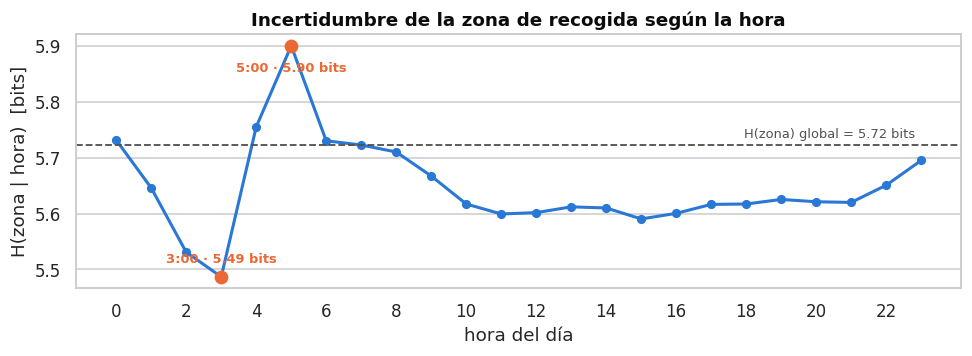

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.4))
curve = hourly_entropy["H(zona|hora) [bits]"]
ax.plot(curve.index, curve.to_numpy(), color=BLUE, lw=2, marker="o", ms=5)
ax.axhline(zone_entropy, color=SOFT_INK, ls="--", lw=1.2)
ax.annotate(f"H(zona) global = {zone_entropy:.2f} bits", xy=(23, zone_entropy), xytext=(-4, 5),
            textcoords="offset points", ha="right", fontsize=8.5, color=SOFT_INK)
for hour, offset in [(curve.idxmin(), 9), (curve.idxmax(), -17)]:
    ax.plot([hour], [curve[hour]], "o", color=ORANGE, ms=8)
    ax.annotate(f"{hour}:00 · {curve[hour]:.2f} bits", xy=(hour, curve[hour]), xytext=(0, offset),
                textcoords="offset points", ha="center", fontsize=8.5, color=ORANGE, weight="bold")
ax.set_title("Incertidumbre de la zona de recogida según la hora")
ax.set_xlabel("hora del día")
ax.set_ylabel("H(zona | hora)  [bits]")
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Lectura.** Con 237 barrios activos, la entropía máxima posible sería 7,89 bits. La real es **5,7221 bits: 53 zonas efectivas**. La demanda está concentrada, pero no tanto como para cubrirla con cuatro o cinco puntos fijos.

El resultado incómodo es el condicional: **H(zona | hora) = 5,6383 bits contra H(zona) = 5,7221**. Saber qué hora es reduce la incertidumbre sobre la zona de recogida en **0,0838 bits, el 1,46 %**. Hora por hora la curva se mueve poco: entre las 3 a.m. (5,49 bits, la más concentrada) y las 5 a.m. (5,90, la más dispersa) hay apenas 0,41 bits, y toda la franja de 10 a 22 h es prácticamente plana.

Para UrbanMove: **una estrategia de posicionamiento basada en el reloj no cambia casi nada el mapa**. Lo que cambia con la hora es el volumen, no el lugar.

In [20]:
# Entropía por contexto usando las variables derivadas (franja, día, festivo).
context_masks = {
    "Madrugada": trips["time_of_day"] == "Late Night",
    "Mañana": trips["time_of_day"] == "Morning",
    "Tarde": trips["time_of_day"] == "Afternoon",
    "Noche": trips["time_of_day"] == "Evening",
    "Día laboral": ~trips["is_weekend"],
    "Fin de semana": trips["is_weekend"],
    "Festivo": trips["is_holiday"],
    "Día no festivo": ~trips["is_holiday"],
}

context_entropy = pd.DataFrame([
    {
        "contexto": name,
        "viajes": int(mask.sum()),
        "H(zona) [bits]": entropy(to_probabilities(
            trips.loc[mask, "pickup_neighborhood"].value_counts().to_numpy())),
        "zona dominante": trips.loc[mask, "pickup_neighborhood"].value_counts().idxmax(),
        "% en top 10 zonas": 100 * trips.loc[mask, "pickup_neighborhood"]
                                 .value_counts(normalize=True).head(10).sum(),
    }
    for name, mask in context_masks.items()
]).set_index("contexto")
context_entropy["zonas efectivas (2^H)"] = 2 ** context_entropy["H(zona) [bits]"]
display(context_entropy.round(2))

,viajes,H(zona) [bits],zona dominante,% en top 10 zonas,zonas efectivas (2^H)
contexto,,,,,
Madrugada,167208,5.73,East Village,41.81,52.97
Mañana,351234,5.70,Upper East Side North,34.86,51.85
Tarde,510802,5.61,Upper East Side South,36.90,49.00
Noche,401929,5.66,Midtown Center,35.63,50.60
Día laboral,1023029,5.68,Upper East Side South,35.44,51.19
Fin de semana,408144,5.80,East Village,31.74,55.56
Festivo,26708,5.81,Penn Station/Madison Sq West,32.71,55.94
Día no festivo,1404465,5.72,Upper East Side South,34.14,52.74


**Lectura.** La madrugada es el único contexto que se comporta distinto: su zona dominante deja de ser el Upper East Side y pasa a ser East Village, y sus 10 zonas principales concentran el 41,8 % de los viajes contra 34–37 % del resto. El fin de semana ocurre lo contrario: la demanda se **dispersa** (5,80 bits, 56 zonas efectivas).

O sea que la ciudad diurna es estable y aburrida; la nocturna y la del fin de semana son las que mueven el mapa.

In [21]:
# Información mutua entre las variables derivadas y el destino del viaje.
variable_pairs = [
    ("hora", trips["hour"], "zona de destino", trips["dropoff_neighborhood"]),
    ("franja del día", trips["time_of_day"], "zona de destino", trips["dropoff_neighborhood"]),
    ("día de la semana", trips["day_name"], "zona de destino", trips["dropoff_neighborhood"]),
    ("fin de semana", trips["is_weekend"], "zona de destino", trips["dropoff_neighborhood"]),
    ("festivo", trips["is_holiday"], "zona de destino", trips["dropoff_neighborhood"]),
    ("zona de recogida", trips["pickup_neighborhood"], "zona de destino", trips["dropoff_neighborhood"]),
    ("distrito de recogida", trips["pickup_borough"], "distrito de destino", trips["dropoff_borough"]),
]

mi_table = pd.DataFrame([
    dict(zip(["X", "Y", "I(X;Y) [bits]", "H(Y) [bits]"], [x_name, y_name, *mutual_information(x, y)]))
    for x_name, x, y_name, y in variable_pairs
])
mi_table["% de H(Y) explicado"] = 100 * mi_table["I(X;Y) [bits]"] / mi_table["H(Y) [bits]"]
display(mi_table.sort_values("% de H(Y) explicado", ascending=False).round(4))

,X,Y,I(X;Y) [bits],H(Y) [bits],% de H(Y) explicado
6,distrito de recogida,distrito de destino,0.0673,0.6621,10.1593
5,zona de recogida,zona de destino,0.4726,6.1383,7.6997
0,hora,zona de destino,0.1126,6.1383,1.8339
1,franja del día,zona de destino,0.0846,6.1383,1.3781
2,día de la semana,zona de destino,0.0111,6.1383,0.1815
3,fin de semana,zona de destino,0.0086,6.1383,0.1404
4,festivo,zona de destino,0.0005,6.1383,0.0076


**Lectura.** Ordenados por información aportada sobre el destino:

1. **Distrito de recogida → distrito de destino: 10,16 %** de H(distrito de destino) = 0,6621 bits. Saber de qué distrito sale el viaje es lo más informativo, porque la mayoría de los viajes se queda dentro del mismo distrito.
2. **Zona de recogida → zona de destino: 7,70 %** (0,4726 bits sobre H(destino) = 6,1383).
3. **Hora: 1,83 %** (0,1126 bits), franja del día 1,38 %.
4. **Día de la semana 0,18 %, fin de semana 0,14 %, festivo 0,008 %**: prácticamente nada.

Un par de advertencias sobre cómo leer esa lista. Primero, **el porcentaje y los bits no ordenan igual**: el distrito explica más en proporción (10,16 % contra 7,70 %), pero en cantidad de información la zona aporta siete veces más, **0,4726 bits contra 0,0673**. Lo que pasa es que cada fila divide por una H(Y) distinta: la del distrito de destino es 0,6621 bits y la de la zona de destino 6,1383. Así que el porcentaje mide *qué fracción de una incertidumbre pequeña* se resuelve, no cuánta incertidumbre se resuelve. Para posicionar conductores lo que importa son los bits. Segundo, todas estas cantidades salen del estimador empírico sin suavizar, calculado sobre una sola tabla conjunta por par de variables; el suavizado de Laplace se reserva para la KL, que es donde un cero haría falta rellenar.

La conclusión operativa es la misma de 4.1 reforzada: **importa de dónde sale el cliente, no cuándo sale**. Un modelo de anticipación de destino que use solo variables de calendario está destinado a fallar.

In [22]:
# Divergencia KL entre contextos: mide cuánto cuesta usar la distribución de un
# contexto para describir el otro. No es simétrica, por eso se reportan las dos direcciones.
def zone_distribution(mask, column="pickup_neighborhood", zones=None):
    counts = trips.loc[mask, column].value_counts()
    counts = counts.reindex(zones if zones is not None else counts.index, fill_value=0)
    return to_probabilities(counts.to_numpy()), counts.index

all_zones = trips["pickup_neighborhood"].value_counts().index
p_weekday, _ = zone_distribution(~trips["is_weekend"], zones=all_zones)
p_weekend, _ = zone_distribution(trips["is_weekend"], zones=all_zones)
p_holiday, _ = zone_distribution(trips["is_holiday"], zones=all_zones)
p_regular, _ = zone_distribution(~trips["is_holiday"], zones=all_zones)
p_rush, _ = zone_distribution(trips["hour"].isin([18, 19]), zones=all_zones)
p_night, _ = zone_distribution(trips["time_of_day"] == "Late Night", zones=all_zones)

kl_table = pd.DataFrame([
    {"p (referencia)": "día laboral", "q (comparación)": "fin de semana",
     "H(p)": entropy(p_weekday), "H(p,q)": cross_entropy(p_weekday, p_weekend),
     "KL(p||q)": kl_divergence(p_weekday, p_weekend), "KL(q||p)": kl_divergence(p_weekend, p_weekday)},
    {"p (referencia)": "día no festivo", "q (comparación)": "festivo",
     "H(p)": entropy(p_regular), "H(p,q)": cross_entropy(p_regular, p_holiday),
     "KL(p||q)": kl_divergence(p_regular, p_holiday), "KL(q||p)": kl_divergence(p_holiday, p_regular)},
    {"p (referencia)": "hora pico (18–19 h)", "q (comparación)": "madrugada",
     "H(p)": entropy(p_rush), "H(p,q)": cross_entropy(p_rush, p_night),
     "KL(p||q)": kl_divergence(p_rush, p_night), "KL(q||p)": kl_divergence(p_night, p_rush)},
])
display(kl_table.round(4))

,p (referencia),q (comparación),H(p),"H(p,q)",KL(p||q),KL(q||p)
0,día laboral,fin de semana,5.6779,5.7332,0.0553,0.0596
1,día no festivo,festivo,5.7210,5.7450,0.0241,0.0287
2,hora pico (18–19 h),madrugada,5.6292,6.0093,0.3801,0.4398


**Lectura.** La KL compara dos contextos midiendo cuántos bits se pierden al describir uno con la distribución del otro. Los tres pares dicen cosas distintas:

- **Laboral contra fin de semana: 0,055 bits.** Bajo. La ciudad no cambia de forma el sábado.
- **No festivo contra festivo: 0,024 bits.** Aún más bajo; los festivos se parecen a un día laboral cualquiera más de lo que se esperaría.
- **Hora pico contra madrugada: 0,38 bits**, siete veces la diferencia entre días. **El contraste real no está entre días, está entre horas del día.**

La asimetría también informa: KL(madrugada || pico) = 0,44 es mayor que KL(pico || madrugada) = 0,38, porque la madrugada tiene zonas activas que en hora pico casi no aparecen, y describirlas con la distribución del pico cuesta más bits.

**Zona por zona** (gráfica siguiente), el promedio bajo esconde un movimiento sistemático: East Village pasa de 2,65 % a 4,70 % de los viajes el fin de semana y Lower East Side de 1,19 % a 2,69 %, mientras Midtown Center cae de 4,06 % a 2,66 %. La demanda se muda del distrito de oficinas a la zona de bares.

**Esto no contradice lo de 4.1.** Allí la información mutua entre hora y zona daba 0,0838 bits, casi nada, y aquí la KL entre pico y madrugada da 0,38. Las dos cosas son ciertas porque miden cosas distintas: la información mutua es un **promedio ponderado por volumen** sobre las 24 horas, y las horas diurnas, que concentran la mayoría de los viajes, se parecen mucho entre sí. La madrugada sí es muy distinta, pero pesa poco en ese promedio. En una frase: **el reloj importa poco en general y mucho en los extremos del día**, y por eso la recomendación no es ignorar la hora sino usarla solo donde el contraste existe.

,zona,% viajes laboral,% viajes fin de semana,aporte a KL [bits]
1,Midtown Center,4.0580,2.6604,0.0247
5,Midtown East,3.7411,2.5066,0.0216
0,Upper East Side South,4.1977,2.9492,0.0214
2,Upper East Side North,3.8219,2.7991,0.0172
13,LaGuardia Airport,2.7588,1.8962,0.0149
27,Lenox Hill East,1.9332,1.2937,0.0112
6,Murray Hill,3.4550,2.7777,0.0109
11,Midtown North,2.8701,2.3508,0.0083
32,Meatpacking/West Village West,1.1802,1.6589,-0.0058
29,Greenwich Village South,1.2939,1.9535,-0.0077


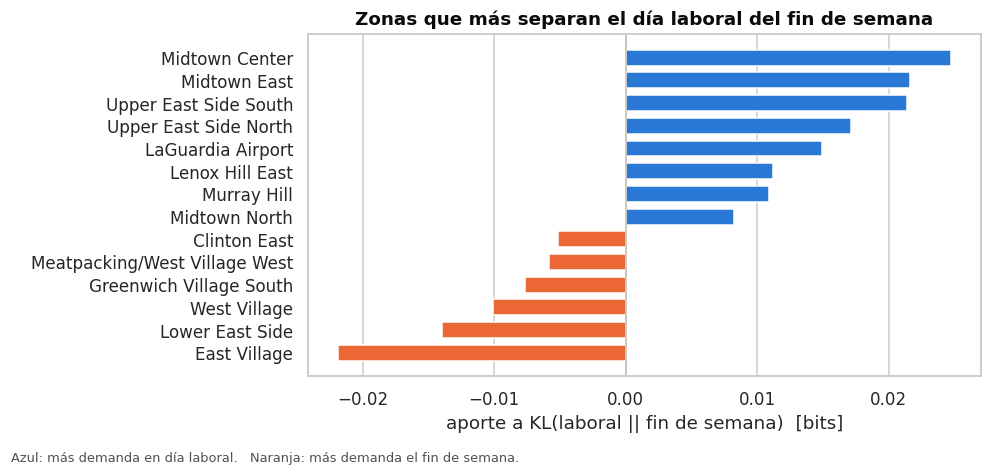

In [23]:
# Descomposición de KL(laboral || fin de semana) zona por zona.
kl_by_zone = pd.DataFrame({
    "zona": all_zones,
    "% viajes laboral": 100 * p_weekday,
    "% viajes fin de semana": 100 * p_weekend,
    "aporte a KL [bits]": p_weekday * np.log2(p_weekday / p_weekend),
}).sort_values("aporte a KL [bits]", ascending=False)
display(pd.concat([kl_by_zone.head(8), kl_by_zone.tail(5)]).round(4))

fig, ax = plt.subplots(figsize=(9, 4.2))
extremes = pd.concat([kl_by_zone.head(8), kl_by_zone.tail(6)]).sort_values("aporte a KL [bits]")
ax.barh(extremes["zona"], extremes["aporte a KL [bits]"], height=0.7,
        color=[ORANGE if v < 0 else BLUE for v in extremes["aporte a KL [bits]"]])
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_title("Zonas que más separan el día laboral del fin de semana")
ax.set_xlabel("aporte a KL(laboral || fin de semana)  [bits]")
ax.grid(axis="y", visible=False)
fig.text(0, -0.02, "Azul: más demanda en día laboral.   Naranja: más demanda el fin de semana.",
         fontsize=8.5, color=SOFT_INK)
plt.tight_layout()
plt.show()

### 4.4 · Jensen y log-sum-exp

Dos herramientas que sostienen el resto del cuaderno:

- **Jensen**: como el logaritmo es cóncavo, E[log X] ≤ log E[X]. La brecha entre la media geométrica y la aritmética mide la asimetría en la misma escala en que después se modelan las variables. Es la razón formal por la que duración y distancia entran en logaritmo a la mezcla del Rol 3.
- **log-sum-exp**: sumar cientos de probabilidades pequeñas en escala lineal termina en cero. Factorizar el máximo evita el desbordamiento. Es exactamente la operación que usa el paso E del EM.

In [24]:
# Jensen: log es cóncava, así que E[log X] <= log E[X]. La brecha entre la media
# geométrica y la aritmética es la asimetría de la variable expresada en la misma escala.
jensen = pd.DataFrame([
    {"variable": name,
     "E[log X]": np.log(values).mean(),
     "log E[X]": np.log(values.mean()),
     "media geométrica": np.exp(np.log(values).mean()),
     "media aritmética": values.mean()}
    for name, values in [("duración (min)", trips["trip_duration_minutes"].to_numpy()),
                         ("distancia (km)", trips["trip_distance"].to_numpy()),
                         ("velocidad (km/h)", trips["speed_kmh"].to_numpy())]
])
# La brecha se calcula con logaritmo natural, asi que esta en NATS, no en bits.
# Se reportan las dos escalas para que no se confunda con las entropias del Rol 1.
jensen["brecha de Jensen [nats]"] = jensen["log E[X]"] - jensen["E[log X]"]
jensen["brecha de Jensen [bits]"] = jensen["brecha de Jensen [nats]"] / np.log(2)
jensen = jensen.rename(columns={"E[log X]": "E[log X] [nats]", "log E[X]": "log E[X] [nats]"})
display(jensen.round(4))

,variable,E[log X] [nats],log E[X] [nats],media geométrica,media aritmética,brecha de Jensen [nats],brecha de Jensen [bits]
0,duración (min),2.3841,2.6373,10.8492,13.9748,0.2532,0.3652
1,distancia (km),0.8390,1.2406,2.3140,3.4575,0.4016,0.5793
2,velocidad (km/h),2.5492,2.6742,12.7975,14.5014,0.1250,0.1803


In [25]:
# log-sum-exp: al combinar log-probabilidades de muchas zonas (o componentes de una
# mezcla) la suma directa de exponenciales se va a cero. Es la misma operación que
# usa el paso E del Rol 3.
zone_log_probs = np.log(to_probabilities(hour_zone.sum(axis=0).to_numpy()))
scaled = zone_log_probs * 1500  # escala típica de una log-verosimilitud con muchos datos

with np.errstate(divide="ignore"):
    lse_check = pd.DataFrame([
        {"método": "directo: log(Σ exp(x))", "resultado": np.log(np.exp(scaled).sum())},
        {"método": "estable: max + log(Σ exp(x − max))", "resultado": log_sum_exp(scaled)},
    ])
display(lse_check)

,método,resultado
0,directo: log(Σ exp(x)),-inf
1,estable: max + log(Σ exp(x − max)),-4888.812585


**Lectura.** La brecha de Jensen es de 0,25 en duración (media geométrica 10,8 min contra aritmética 14,0) y de 0,40 en distancia (2,31 km contra 3,46). Reportarle a UrbanMove el promedio de duración sobreestima el viaje típico en tres minutos.

En el log-sum-exp, la suma directa devuelve **-inf** (todas las exponenciales se van a cero en punto flotante) mientras la versión estable devuelve el valor correcto. Sin este truco, el paso E del Rol 3 no correría.

## 5. Segmentación por partición · Rol 2

**Bloque temático:** K-means, clustering jerárquico, DBSCAN, métricas de validación y selección de hiperparámetros.

**Pregunta:** si la hora no dice dónde estará la demanda, ¿dónde están los polos estables que sí conviene cubrir?

Se comparan dos métodos con supuestos opuestos: K-means obliga a que todo viaje pertenezca a un grupo; DBSCAN acepta que haya viajes que no pertenecen a ninguno. Esa diferencia es justamente la que se necesita para decidir qué hacer con las zonas dispersas.

In [26]:
# --- Preparación de la muestra espacial ---
# Silueta es O(n²) y DBSCAN sobre 1,4 millones de puntos no cabe en memoria, así que
# se trabaja con una muestra aleatoria fija. Las coordenadas se proyectan a metros con
# una aproximación plana local: el error crece con la distancia al punto de referencia y
# es del orden de metros en los extremos de la muestra (los viajes a JFK), despreciable
# frente a un eps de cientos de metros. Permite leer eps y las distancias en unidades reales.
spatial_sample = trips.sample(SAMPLE_SIZE, random_state=SEED)

METERS_PER_DEGREE = 111_320.0
ref_lat = spatial_sample["pickup_latitude"].mean()
coords = np.column_stack([
    (spatial_sample["pickup_longitude"] - spatial_sample["pickup_longitude"].mean())
    * METERS_PER_DEGREE * np.cos(np.radians(ref_lat)),
    (spatial_sample["pickup_latitude"] - ref_lat) * METERS_PER_DEGREE,
])

silhouette_idx = np.random.default_rng(SEED).choice(len(coords), 10_000, replace=False)

,inercia (SSE),silueta,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,5.439610e+11,0.808,0.169,8959.192
3,2.800351e+11,0.458,0.595,13310.913
4,1.857484e+11,0.496,0.494,15533.118
5,1.209932e+11,0.457,0.554,19280.606
6,9.548315e+10,0.408,0.644,20040.627
7,8.179701e+10,0.406,0.678,19771.446
8,7.038405e+10,0.412,0.699,20126.156
9,6.225090e+10,0.393,0.711,20056.859
10,5.423813e+10,0.396,0.703,20662.068


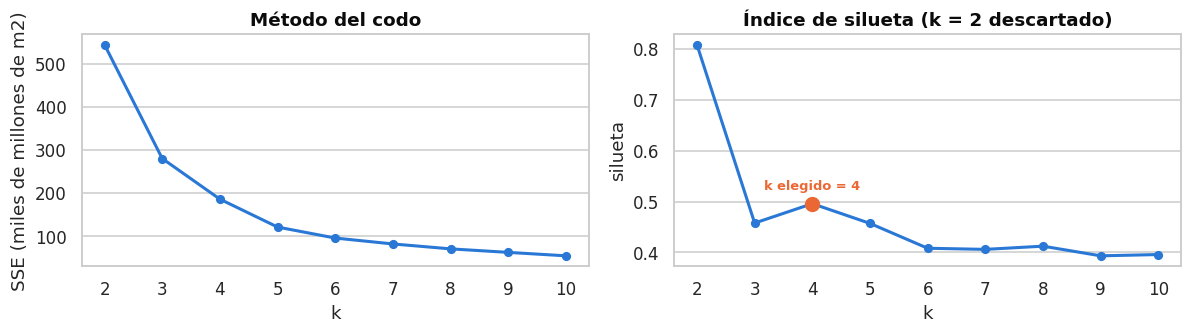

In [27]:
# Barrido de k con cuatro métricas de validación.
kmeans_metrics = pd.DataFrame([
    {
        "k": k,
        "inercia (SSE)": model.inertia_,
        "silueta": silhouette_score(coords[silhouette_idx], model.labels_[silhouette_idx]),
        "Davies-Bouldin": davies_bouldin_score(coords[silhouette_idx], model.labels_[silhouette_idx]),
        "Calinski-Harabasz": calinski_harabasz_score(coords[silhouette_idx], model.labels_[silhouette_idx]),
    }
    for k, model in ((k, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(coords))
                     for k in range(2, 11))
]).set_index("k")

# k = 2 maximiza la silueta pero solo separa Manhattan de los aeropuertos: se descarta
# por falta de uso operativo y se elige el mejor k a partir de 4, donde el SSE ya se aplanó.
best_k = int(kmeans_metrics.loc[4:, "silueta"].idxmax())
display(kmeans_metrics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(kmeans_metrics.index, kmeans_metrics["inercia (SSE)"] / 1e9, color=BLUE, lw=2, marker="o", ms=5)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("SSE (miles de millones de m2)")
axes[1].plot(kmeans_metrics.index, kmeans_metrics["silueta"], color=BLUE, lw=2, marker="o", ms=5)
axes[1].plot([best_k], [kmeans_metrics.loc[best_k, "silueta"]], "o", color=ORANGE, ms=9)
axes[1].annotate(f"k elegido = {best_k}", xy=(best_k, kmeans_metrics.loc[best_k, "silueta"]),
                 xytext=(0, 9), textcoords="offset points", ha="center", color=ORANGE,
                 fontsize=8.5, weight="bold")
axes[1].set_title("Índice de silueta (k = 2 descartado)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silueta")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Decisión sobre k.** El máximo global de la silueta está en k = 2 con 0,808, pero esa partición solo separa "Manhattan" de "los aeropuertos": es limpia y no sirve para posicionar conductores. El SSE deja de caer bruscamente a partir de k = 4, y entre los k ≥ 4 la mejor silueta es la de k = 4. El criterio no es el número más alto, sino el mejor número entre los que responden la pregunta.

In [28]:
# Modelo final y perfil operativo de cada grupo.
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(coords)
spatial_sample = spatial_sample.assign(kmeans_cluster=kmeans.labels_)

kmeans_profile = (spatial_sample.groupby("kmeans_cluster", observed=True)
                  .agg(viajes=("id", "size"),
                       barrio_dominante=("pickup_neighborhood", lambda s: s.mode().iat[0]),
                       distrito=("pickup_borough", lambda s: s.mode().iat[0]),
                       duracion_mediana=("trip_duration_minutes", "median"),
                       distancia_mediana=("trip_distance", "median"),
                       velocidad_mediana=("speed_kmh", "median"),
                       hora_pico=("hour", lambda s: int(s.value_counts().idxmax())),
                       pct_fin_de_semana=("is_weekend", lambda s: 100 * s.mean())))
kmeans_profile["% de la muestra"] = 100 * kmeans_profile["viajes"] / len(spatial_sample)
display(kmeans_profile.round(2))

,viajes,barrio_dominante,distrito,duracion_mediana,distancia_mediana,velocidad_mediana,hora_pico,pct_fin_de_semana,% de la muestra
kmeans_cluster,,,,,,,,,
0,21901,Union Sq,Manhattan,11.08,2.11,12.58,22,32.27,43.80
1,1132,JFK Airport,Queens,38.39,19.76,26.89,20,29.06,2.26
2,25406,Upper East Side South,Manhattan,10.22,1.96,12.66,18,25.99,50.81
3,1561,LaGuardia Airport,Queens,26.20,9.29,19.17,18,24.02,3.12


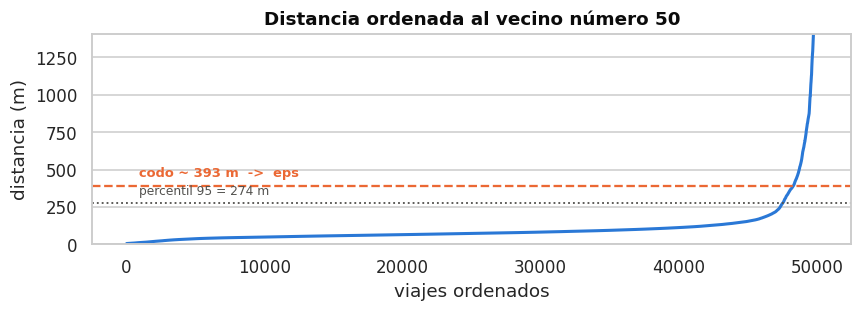

In [29]:
# eps de DBSCAN a partir de la curva de distancia al vecino min_samples. El corte es el
# codo real de la curva (punto más alejado de la recta que une los extremos), con la misma
# función elbow_index que elige K en el Rol 3. Se reporta al lado el percentil 95 para
# dejar ver qué habría dado una regla por cuantil, que fija el ruido por construcción.
MIN_SAMPLES = 50
neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(coords)
k_distance = np.sort(neighbors.kneighbors(coords)[0][:, -1])

knee_position = elbow_index(pd.Series(k_distance))
eps = float(k_distance[knee_position])
eps_p95 = float(np.percentile(k_distance, 95))
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.arange(len(k_distance)), k_distance, color=BLUE, lw=2)
ax.axhline(eps, color=ORANGE, ls="--", lw=1.5)
ax.annotate(f"codo ~ {fmt(eps)} m  ->  eps", xy=(0, eps), xytext=(8, 6), textcoords="offset points",
            color=ORANGE, fontsize=8.5, weight="bold")
ax.axhline(eps_p95, color=SOFT_INK, ls=":", lw=1.2)
ax.annotate(f"percentil 95 = {fmt(eps_p95)} m", xy=(0, eps_p95), xytext=(8, 6),
            textcoords="offset points", color=SOFT_INK, fontsize=8)
ax.set_title(f"Distancia ordenada al vecino número {MIN_SAMPLES}")
ax.set_xlabel("viajes ordenados")
ax.set_ylabel("distancia (m)")
ax.set_ylim(0, np.percentile(k_distance, 99.5))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

dbscan = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(coords)
spatial_sample = spatial_sample.assign(dbscan_cluster=dbscan.labels_)
is_signal = dbscan.labels_ != -1
n_dense = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)

In [30]:
# La regla alternativa: el percentil 95 de la curva de k-distancia, que es el cuantil
# que no usamos. Se corre aqui para poder reportar su ruido real.
dbscan_p95 = DBSCAN(eps=eps_p95, min_samples=MIN_SAMPLES).fit(coords)
noise_p95 = 100 * (dbscan_p95.labels_ == -1).mean()
n_dense_p95 = len(set(dbscan_p95.labels_)) - (1 if -1 in dbscan_p95.labels_ else 0)

dbscan_rules = pd.DataFrame([
    {"regla": f"codo de la curva (usada)", "eps [m]": round(eps, 1),
     "nucleos densos": n_dense, "% de ruido": round(100 * (~is_signal).mean(), 2)},
    {"regla": "percentil 95 (alternativa)", "eps [m]": round(eps_p95, 1),
     "nucleos densos": n_dense_p95, "% de ruido": round(noise_p95, 2)},
])
display(dbscan_rules)


,regla,eps [m],nucleos densos,% de ruido
0,codo de la curva (usada),393.2,7,2.40
1,percentil 95 (alternativa),273.6,5,4.19


In [31]:
# Comparación de los dos métodos sobre la misma muestra.
method_comparison = pd.DataFrame([
    {"método": f"K-means (k={best_k})", "grupos": best_k, "% de ruido": 0.0,
     "silueta": silhouette_score(coords[silhouette_idx], kmeans.labels_[silhouette_idx]),
     "Davies-Bouldin": davies_bouldin_score(coords[silhouette_idx], kmeans.labels_[silhouette_idx])},
    {"método": f"DBSCAN (eps={eps:.0f} m, min_samples={MIN_SAMPLES})", "grupos": n_dense,
     "% de ruido": 100 * (~is_signal).mean(),
     "silueta": silhouette_score(coords[is_signal][:10_000], dbscan.labels_[is_signal][:10_000]),
     "Davies-Bouldin": davies_bouldin_score(coords[is_signal][:10_000], dbscan.labels_[is_signal][:10_000])},
])
display(method_comparison.round(3))

# Caracterización del ruido: define si se trata como error o como demanda dispersa real.
noise = spatial_sample[~is_signal]
noise_profile = pd.DataFrame({
    "ruido (DBSCAN = -1)": [len(noise),
                            noise["trip_duration_minutes"].median(),
                            noise["trip_distance"].median(),
                            100 * noise["is_weekend"].mean(),
                            noise["pickup_borough"].value_counts(normalize=True).head(1).iat[0] * 100,
                            noise["pickup_borough"].value_counts().idxmax()],
    "resto de la muestra": [int(is_signal.sum()),
                            spatial_sample.loc[is_signal, "trip_duration_minutes"].median(),
                            spatial_sample.loc[is_signal, "trip_distance"].median(),
                            100 * spatial_sample.loc[is_signal, "is_weekend"].mean(),
                            spatial_sample.loc[is_signal, "pickup_borough"]
                                .value_counts(normalize=True).head(1).iat[0] * 100,
                            spatial_sample.loc[is_signal, "pickup_borough"].value_counts().idxmax()],
}, index=["viajes", "duración mediana (min)", "distancia mediana (km)", "% fin de semana",
          "% en el distrito dominante", "distrito dominante"])
display(noise_profile)
display(noise["pickup_borough"].value_counts(normalize=True).mul(100).round(1).head(5)
        .rename("% del ruido").to_frame())

# --- Comparacion estricta: los dos metodos sobre EXACTAMENTE el mismo subconjunto ---
# La tabla de arriba evalua cada metodo sobre el subconjunto que le corresponde por su
# propia definicion (K-means sobre todos los puntos, DBSCAN solo sobre los de senal), y
# eso favorece a DBSCAN porque le quita el ruido de encima. Aqui se repite la medicion
# sobre un mismo subconjunto aleatorio de puntos de senal, para que la comparacion sea
# sobre lo mismo en los dos casos.
common_idx = np.random.default_rng(SEED).choice(np.flatnonzero(is_signal),
                                                size=min(10_000, int(is_signal.sum())),
                                                replace=False)
strict_comparison = pd.DataFrame([
    {"metodo": f"K-means (k={best_k})",
     "silueta": silhouette_score(coords[common_idx], kmeans.labels_[common_idx]),
     "Davies-Bouldin": davies_bouldin_score(coords[common_idx], kmeans.labels_[common_idx])},
    {"metodo": f"DBSCAN (eps={eps:.0f} m)",
     "silueta": silhouette_score(coords[common_idx], dbscan.labels_[common_idx]),
     "Davies-Bouldin": davies_bouldin_score(coords[common_idx], dbscan.labels_[common_idx])},
])
strict_comparison.insert(1, "puntos evaluados", len(common_idx))
display(strict_comparison.round(3))


,método,grupos,% de ruido,silueta,Davies-Bouldin
0,K-means (k=4),4,0.000,0.496,0.494
1,"DBSCAN (eps=393 m, min_samples=50)",7,2.396,0.333,0.426


,ruido (DBSCAN = -1),resto de la muestra
viajes,1198,48802
duración mediana (min),11.275,11.066667
distancia mediana (km),3.0575,2.117204
% fin de semana,37.479132,28.535716
% en el distrito dominante,42.821369,94.203106
distrito dominante,Queens,Manhattan


,% del ruido
pickup_borough,
Queens,42.8
Brooklyn,37.6
Manhattan,17.4
Bronx,2.2


,metodo,puntos evaluados,silueta,Davies-Bouldin
0,K-means (k=4),10000,0.505,0.453
1,DBSCAN (eps=393 m),10000,0.322,0.432


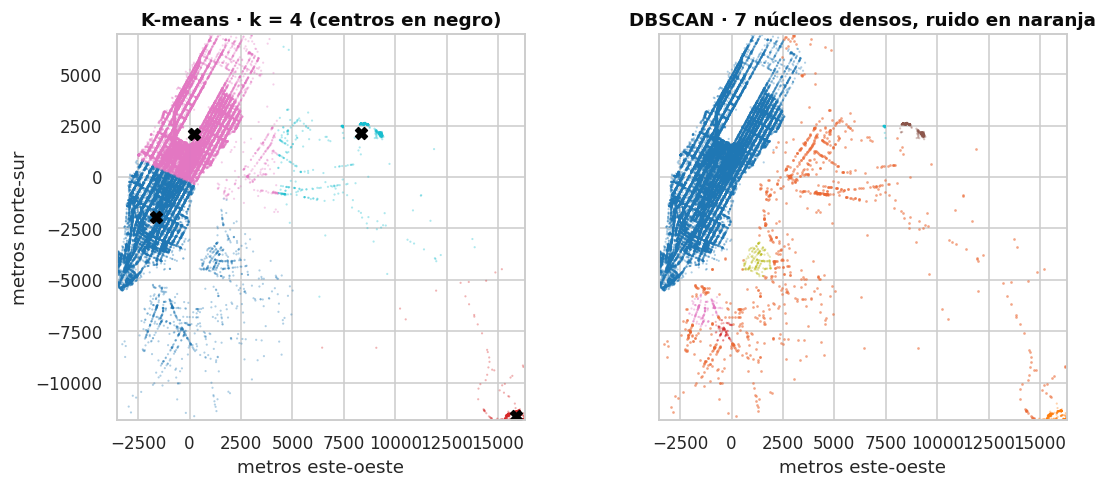

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
axes[0].scatter(coords[:, 0], coords[:, 1], c=kmeans.labels_, cmap="tab10", s=2, alpha=0.35, linewidths=0)
axes[0].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                c="black", s=60, marker="X")
axes[0].set_title(f"K-means · k = {best_k} (centros en negro)")
axes[1].scatter(coords[is_signal, 0], coords[is_signal, 1], c=dbscan.labels_[is_signal],
                cmap="tab10", s=2, alpha=0.35, linewidths=0)
axes[1].scatter(coords[~is_signal, 0], coords[~is_signal, 1], c=ORANGE, s=3, alpha=0.6, linewidths=0)
axes[1].set_title(f"DBSCAN · {n_dense} núcleos densos, ruido en naranja")
for ax in axes:
    ax.set_xlabel("metros este-oeste")
    ax.set_aspect("equal")
    ax.set_xlim(np.percentile(coords[:, 0], [0.5, 99.5]))
    ax.set_ylim(np.percentile(coords[:, 1], [0.5, 99.5]))
axes[0].set_ylabel("metros norte-sur")
plt.tight_layout()
plt.show()

### Lectura

**K-means con k = 4** separa cuatro polos. Dos de ellos, Union Sq (43,8 % de la muestra) y Upper East Side South (50,8 %), reúnen el 95 % de los viajes con duraciones de 10 a 11 minutos y unos 2 km. Los otros dos son los aeropuertos: LaGuardia, con el 3,1 % de los viajes y 26,2 minutos de mediana, y JFK, con el 2,3 % y 38,4 minutos. JFK tiene su pico a las 20 h y LaGuardia a las 18 h. Los aeropuertos son un negocio aparte: duran entre dos y cuatro veces lo que dura un viaje urbano.

**DBSCAN con eps = 393 m y min_samples = 50** encuentra 7 núcleos densos y deja el **2,40 % de los viajes como ruido**. El eps sale del codo real de la curva de distancia al vecino 50, no de un cuantil: la celda imprime al lado el percentil 95, que habría dado 274 m, para dejar claro que una regla por cuantil fija el ruido por construcción (tope de 5 %) y no lo descubre.

Ese ruido no es error. El 43 % sale de Queens, el 38 % de Brooklyn y el 17 % de Manhattan, con distancia mediana de 3,1 km contra 2,1 km del resto y más peso de fin de semana, 37,5 % contra 28,5 %. Es demanda real y dispersa, fuera de los corredores densos.

**Comparación.** K-means gana en silueta, 0,496 contra 0,333, y DBSCAN gana en Davies-Bouldin, 0,426 contra 0,494. Hay que decir algo que juega **a favor de DBSCAN** y aun así no le alcanza: su silueta se calcula solo sobre los puntos de señal, excluyendo el ruido, que son justamente los que peor encajarían en cualquier grupo. Con esa ventaja incluida sigue por debajo, porque sus núcleos son alargados y desiguales mientras K-means impone grupos compactos.

Ninguna de las dos métricas decide el punto, porque los dos métodos responden preguntas distintas. K-means asigna todo viaje a un centro, incluso uno de Queens que queda a kilómetros, y por eso sirve para resumir **en qué grandes áreas se concentra la flota base**. DBSCAN se niega a asignar ese viaje, y por eso sirve para señalar **qué viajes no justifican flota fija**. Para el negocio se complementan.

**Tratamiento del ruido propuesto:** atención bajo demanda, donde el conductor se desplaza cuando entra la solicitud, y exclusión de esos viajes del cálculo del tiempo de espera prometido, porque inflarían el promedio de toda la ciudad.

## 6. Mezclas y variables latentes · Rol 3

**Bloque temático:** modelos de mezcla gaussiana, variables latentes, algoritmo EM, convergencia e inicialización.

**Pregunta:** el Rol 2 respondió *dónde*. Este bloque responde *qué tipo de viaje* ocurre, sin imponer categorías inventadas por el equipo.

Un modelo de mezcla no asigna cada viaje a un grupo: le da una **probabilidad de pertenencia** a cada perfil. Esa es la diferencia con K-means y es lo que permite reconocer viajes que están entre dos perfiles.

In [33]:
# --- Espacio de características del viaje ---
# Duración y distancia entran en logaritmo por su asimetría; la hora entra como seno y
# coseno porque es circular (23 y 0 son adyacentes) y una escala lineal las separaría.
mixture_sample = trips.sample(SAMPLE_SIZE, random_state=SEED).copy()
mixture_sample["log_duration"] = np.log(mixture_sample["trip_duration_minutes"])
mixture_sample["log_distance"] = np.log(mixture_sample["trip_distance"])
mixture_sample["hour_sin"] = np.sin(2 * np.pi * mixture_sample["hour"] / 24)
mixture_sample["hour_cos"] = np.cos(2 * np.pi * mixture_sample["hour"] / 24)

# Sobre speed_kmh. Es cierto que la velocidad es distancia / duracion y por tanto funcion
# determinista de las otras dos: la covarianza queda mal condicionada y de ahi viene la
# regularizacion 1e-6 del EM. Aun asi se conserva, y la razon la medimos en la 6.4:
# el ajuste sin ella (seccion 6.4) degenera. Sin velocidad, la unica estructura que queda
# es la de los angulos horarios, que solo toman 24 valores, y las componentes colapsan
# sobre horas concretas: la certeza media sube a 1,000 con cero viajes ambiguos, K pasa a
# 5 y los perfiles dejan de distinguir tipos de viaje. La variable degenerada que hace
# dano no es la velocidad, es la hora circular; quitar la velocidad solo deja que esa
# degeneracion domine. Se reporta el modelo de cinco variables y se documenta la prueba.
FEATURES = ["log_duration", "log_distance", "speed_kmh", "hour_sin", "hour_cos"]
scaler = StandardScaler().fit(mixture_sample[FEATURES])
X = scaler.transform(mixture_sample[FEATURES])

,BIC,AIC,log-verosimilitud media,iteraciones,mejora del BIC
componentes,,,,,
2,438906.03,438544.42,-4.38,11,
3,346750.28,346203.46,-3.46,43,21.0%
4,366394.98,365662.94,-3.65,18,-5.7%
5,298045.27,297128.01,-2.97,36,18.7%
6,287722.99,286620.52,-2.86,39,3.5%
7,235002.93,233715.24,-2.33,34,18.3%
8,205683.66,204210.76,-2.04,46,12.5%


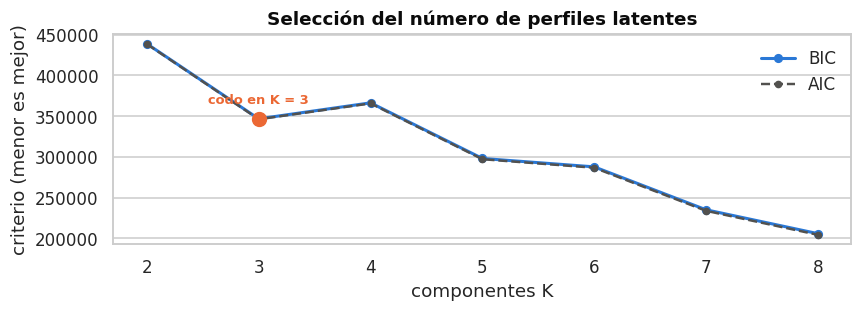

In [34]:
# Seleccion de K. El minimo del BIC dentro del rango probado cae en el borde superior,
# lo que indica que el criterio no se ha estabilizado: con densidades que no son
# gaussianas el EM gasta componentes nuevos en parchear la forma de la densidad, no en
# encontrar grupos. Un minimo en el borde no es un minimo, es senal de donde se dejo de
# buscar. Por eso K se elige por el codo de la curva (punto mas alejado de la recta que
# une los extremos) y se justifica por parsimonia e interpretabilidad, no como minimo
# absoluto del BIC. La columna "mejora del BIC" deja ver cuanto aporta cada componente.
# elbow_index está definida en el bloque de utilidades, porque el Rol 2 la usa también.

mixture_selection = pd.DataFrame([
    {"componentes": k, "BIC": model.bic(X), "AIC": model.aic(X),
     "log-verosimilitud media": model.score(X), "iteraciones": model.n_iter_}
    for k, model in ((k, GaussianMixture(k, covariance_type="full", random_state=SEED,
                                         n_init=3, max_iter=500).fit(X))
                     for k in range(2, 9))
]).set_index("componentes")
mixture_selection["mejora del BIC"] = (
    -mixture_selection["BIC"].diff() / mixture_selection["BIC"].abs().shift()
).map(lambda v: f"{v:.1%}" if pd.notna(v) else "")

n_components = elbow_index(mixture_selection["BIC"])
display(mixture_selection.round(2))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(mixture_selection.index, mixture_selection["BIC"], color=BLUE, lw=2, marker="o", ms=5, label="BIC")
ax.plot(mixture_selection.index, mixture_selection["AIC"], color=SOFT_INK, lw=1.6, ls="--",
        marker="o", ms=4, label="AIC")
ax.plot([n_components], [mixture_selection.loc[n_components, "BIC"]], "o", color=ORANGE, ms=9)
ax.annotate(f"codo en K = {n_components}", xy=(n_components, mixture_selection.loc[n_components, "BIC"]),
            xytext=(0, 10), textcoords="offset points", ha="center", color=ORANGE,
            fontsize=8.5, weight="bold")
ax.set_title("Selección del número de perfiles latentes")
ax.set_xlabel("componentes K")
ax.set_ylabel("criterio (menor es mejor)")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 6.2 · EM implementado paso a paso

El código siguiente **no usa `sklearn.mixture` para ajustar**: implementa el EM completo y deja a sklearn solo como control del resultado final.

- **Paso E.** Con los parámetros actuales (pesos π, medias μ, covarianzas Σ) se calcula para cada viaje la probabilidad de haber sido generado por cada componente: la responsabilidad r(i,k). Todo en logaritmos, normalizado con **log-sum-exp**, porque con cinco variables las densidades son números diminutos.
- **Paso M.** Con esas responsabilidades como pesos se recalculan los parámetros: π es el peso promedio de cada componente, μ la media ponderada de los viajes y Σ su covarianza ponderada.
- **Convergencia.** Cada iteración garantiza que la log-verosimilitud no decrezca. Se detiene cuando la mejora baja de 1e-6 o a las 300 iteraciones.

,inicialización,iteraciones,log-verosimilitud final
0,kmeans++,75.0,-3.45896
1,aleatoria,71.0,-3.45895
2,sklearn (control),NaN,-3.46079


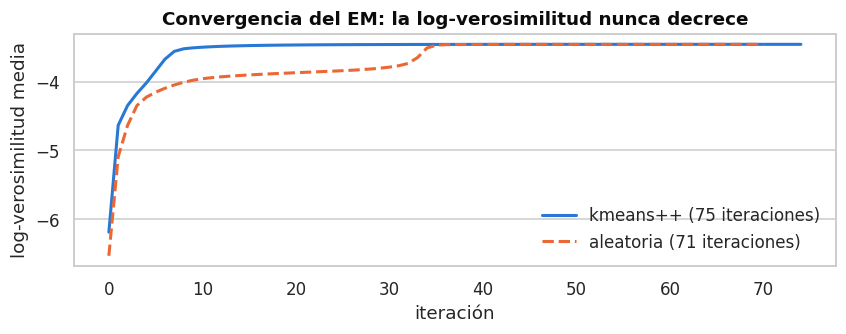

In [35]:
# --- EM implementado directamente ---

def log_gaussian(X, mean, cov):
    """log N(x | mean, cov) por fila, resuelto con Cholesky (sin invertir la covarianza)."""
    dim = X.shape[1]
    chol = np.linalg.cholesky(cov + 1e-6 * np.eye(dim))
    solved = np.linalg.solve(chol, (X - mean).T)
    mahalanobis = (solved ** 2).sum(axis=0)
    log_det = 2 * np.log(np.diag(chol)).sum()
    return -0.5 * (dim * np.log(2 * np.pi) + log_det + mahalanobis)

def log_sum_exp_rows(matrix):
    """Versión por filas de log_sum_exp, usada para normalizar las responsabilidades."""
    peak = matrix.max(axis=1, keepdims=True)
    return (peak + np.log(np.exp(matrix - peak).sum(axis=1, keepdims=True))).ravel()

def fit_gaussian_mixture(X, n_components, init="kmeans++", seed=SEED, max_iter=300, tol=1e-6):
    """EM completo para una mezcla gaussiana con covarianzas libres.

    Devuelve pesos, medias, covarianzas, responsabilidades y la traza de la
    log-verosimilitud para poder graficar la convergencia.
    """
    n_samples, dim = X.shape
    rng = np.random.default_rng(seed)

    if init == "kmeans++":
        means, _ = kmeans_plusplus(X, n_clusters=n_components, random_state=seed)
    else:
        means = X[rng.choice(n_samples, n_components, replace=False)]
    covariances = np.array([np.cov(X.T) for _ in range(n_components)])
    weights = np.full(n_components, 1 / n_components)
    trace = []

    for iteration in range(max_iter):
        # Paso E: responsabilidad de cada componente sobre cada viaje, en logaritmos.
        log_joint = np.column_stack([
            np.log(weights[k]) + log_gaussian(X, means[k], covariances[k])
            for k in range(n_components)
        ])
        log_evidence = log_sum_exp_rows(log_joint)
        responsibilities = np.exp(log_joint - log_evidence[:, None])
        trace.append(log_evidence.mean())

        # Paso M: parámetros de máxima verosimilitud ponderados por las responsabilidades.
        counts = responsibilities.sum(axis=0) + 1e-10
        weights = counts / n_samples
        means = (responsibilities.T @ X) / counts[:, None]
        for k in range(n_components):
            centered = X - means[k]
            covariances[k] = (responsibilities[:, k, None] * centered).T @ centered / counts[k]

        if iteration > 0 and abs(trace[-1] - trace[-2]) < tol:
            break

    return {"weights": weights, "means": means, "covariances": covariances,
            "responsibilities": responsibilities, "trace": trace, "iterations": iteration + 1}

em_kmeanspp = fit_gaussian_mixture(X, n_components, init="kmeans++")
em_random = fit_gaussian_mixture(X, n_components, init="random")

em_runs = pd.DataFrame([
    {"inicialización": "kmeans++", "iteraciones": em_kmeanspp["iterations"],
     "log-verosimilitud final": em_kmeanspp["trace"][-1]},
    {"inicialización": "aleatoria", "iteraciones": em_random["iterations"],
     "log-verosimilitud final": em_random["trace"][-1]},
    {"inicialización": "sklearn (control)", "iteraciones": np.nan,
     "log-verosimilitud final": GaussianMixture(n_components, covariance_type="full",
                                                random_state=SEED).fit(X).score(X)},
])
display(em_runs.round(5))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(em_kmeanspp["trace"], color=BLUE, lw=2, label=f"kmeans++ ({em_kmeanspp['iterations']} iteraciones)")
ax.plot(em_random["trace"], color=ORANGE, lw=2, ls="--", label=f"aleatoria ({em_random['iterations']} iteraciones)")
ax.set_title("Convergencia del EM: la log-verosimilitud nunca decrece")
ax.set_xlabel("iteración")
ax.set_ylabel("log-verosimilitud media")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [36]:
# Perfiles resultantes. La asignación es blanda: cada viaje tiene una probabilidad de
# pertenencia por componente y se reporta la máxima como medida de certeza.
# Las componentes salen en el orden en que el EM las inicializó, que no es estable entre
# ejecuciones ni entre máquinas. Se reordenan por velocidad media creciente para que el
# perfil 0 sea siempre el más lento y los textos no dependan del orden del ajuste.
# El orden se reconstruye de las medias y no leyendo la columna speed_kmh, para que el
# codigo siga siendo valido en la prueba de sensibilidad, donde esa columna no existe:
# log(velocidad km/h) = log_distancia - log_duracion + log(60), en unidades originales.
raw_means = scaler.inverse_transform(em_kmeanspp["means"])
dur_col, dist_col = FEATURES.index("log_duration"), FEATURES.index("log_distance")
log_speed = raw_means[:, dist_col] - raw_means[:, dur_col] + np.log(60)
order = np.argsort(log_speed)
responsibilities = em_kmeanspp["responsibilities"][:, order]
sorted_weights = em_kmeanspp["weights"][order]

mixture_sample["profile"] = responsibilities.argmax(axis=1)
mixture_sample["confidence"] = responsibilities.max(axis=1)

profile_summary = (mixture_sample.groupby("profile", observed=True)
                   .agg(viajes=("id", "size"),
                        duracion_mediana=("trip_duration_minutes", "median"),
                        distancia_mediana=("trip_distance", "median"),
                        velocidad_mediana=("speed_kmh", "median"),
                        hora_tipica=("hour", lambda s: int(s.value_counts().idxmax())),
                        franja_dominante=("time_of_day", lambda s: s.mode().iat[0]),
                        pct_fin_de_semana=("is_weekend", lambda s: 100 * s.mean()),
                        pct_festivo=("is_holiday", lambda s: 100 * s.mean()),
                        barrio_dominante=("pickup_neighborhood", lambda s: s.mode().iat[0]),
                        certeza_media=("confidence", "mean")))
profile_summary["peso pi [%]"] = (100 * sorted_weights).round(2)
profile_summary["% de la muestra"] = 100 * profile_summary["viajes"] / len(mixture_sample)
display(profile_summary.round(2))

confidence_report = pd.DataFrame({
    "métrica": ["certeza media", "viajes con certeza < 0,6", "viajes con certeza > 0,9"],
    "valor": [f"{mixture_sample['confidence'].mean():.3f}",
              f"{(mixture_sample['confidence'] < 0.6).mean():.2%}",
              f"{(mixture_sample['confidence'] > 0.9).mean():.2%}"],
})
display(confidence_report)
display(pd.DataFrame(responsibilities[:5].round(3),
                     columns=[f"perfil {k}" for k in range(n_components)]))

,viajes,duracion_mediana,distancia_mediana,velocidad_mediana,hora_tipica,franja_dominante,pct_fin_de_semana,pct_festivo,barrio_dominante,certeza_media,peso pi [%],% de la muestra
profile,,,,,,,,,,,,
0,16679,12.03,1.47,7.98,18,Afternoon,20.73,0.97,Midtown Center,0.98,33.52,33.36
1,20139,9.95,2.23,13.51,21,Afternoon,30.62,1.94,Upper East Side North,0.97,39.96,40.28
2,13182,11.78,4.44,22.38,22,Evening,36.04,2.94,JFK Airport,0.99,26.52,26.36


,métrica,valor
0,certeza media,0.978
1,"viajes con certeza < 0,6",1.25%
2,"viajes con certeza > 0,9",93.21%


,perfil 0,perfil 1,perfil 2
0,0.000,0.000,1.0
1,1.000,0.000,0.0
2,0.000,0.000,1.0
3,0.001,0.999,0.0
4,1.000,0.000,0.0


In [37]:
# --- Parametros finales de la mezcla ---
# Se reportan en unidades ORIGINALES, no en el espacio estandarizado: las medias se
# deshacen con el scaler y las covarianzas con Sigma_orig = D Sigma D, D = diag(escala).
scale_vector = scaler.scale_
raw_means_sorted = scaler.inverse_transform(em_kmeanspp["means"])[order]
raw_covs = np.array([np.diag(scale_vector) @ c @ np.diag(scale_vector)
                     for c in em_kmeanspp["covariances"][order]])

final_parameters = pd.DataFrame({"peso pi [%]": (100 * sorted_weights).round(2)})
for j, feature in enumerate(FEATURES):
    final_parameters[f"mu {feature}"] = raw_means_sorted[:, j].round(4)
for j, feature in enumerate(FEATURES):
    final_parameters[f"sigma {feature}"] = np.sqrt(raw_covs[:, j, j]).round(4)
final_parameters.index.name = "componente"
display(final_parameters)

# Los mismos parametros leidos en unidades de negocio. exp(media de un logaritmo) es la
# media geometrica, que en una lognormal es la mediana: el mismo punto que la brecha de
# Jensen del Rol 1 decia que habia que reportar en lugar del promedio.
interpretable = pd.DataFrame({
    "peso pi [%]": (100 * sorted_weights).round(2),
    "duracion mediana [min]": np.exp(raw_means_sorted[:, FEATURES.index("log_duration")]).round(2),
    "distancia mediana [km]": np.exp(raw_means_sorted[:, FEATURES.index("log_distance")]).round(2),
    "hora media del componente": ((np.degrees(np.arctan2(
        raw_means_sorted[:, FEATURES.index("hour_sin")],
        raw_means_sorted[:, FEATURES.index("hour_cos")])) % 360) / 15).round(1),
})
interpretable["velocidad implicita [km/h]"] = (
    60 * interpretable["distancia mediana [km]"] / interpretable["duracion mediana [min]"]).round(2)
interpretable.index.name = "componente"
display(interpretable)

# Matrices de covarianza completas, una por componente, apiladas en un solo cuadro.
covarianzas = pd.concat(
    {k: pd.DataFrame(raw_covs[k].round(4), index=FEATURES, columns=FEATURES)
     for k in range(n_components)},
    names=["componente", "variable"])
display(covarianzas)


,peso pi [%],mu log_duration,mu log_distance,mu speed_kmh,mu hour_sin,mu hour_cos,sigma log_duration,sigma log_distance,sigma speed_kmh,sigma hour_sin,sigma hour_cos
componente,,,,,,,,,,,
0,33.52,2.4733,0.3813,7.7027,-0.2530,-0.3219,0.5934,0.6182,1.9466,0.6546,0.6355
1,39.96,2.3123,0.8228,13.6718,-0.2469,-0.0331,0.7004,0.7121,1.9750,0.6681,0.7011
2,26.52,2.3858,1.4588,24.5333,-0.0752,0.1499,0.8831,0.9366,6.8618,0.6906,0.7036


,peso pi [%],duracion mediana [min],distancia mediana [km],hora media del componente,velocidad implicita [km/h]
componente,,,,,
0,33.52,11.86,1.46,14.5,7.39
1,39.96,10.10,2.28,17.5,13.54
2,26.52,10.87,4.30,22.2,23.74


log_duration  log_distance  speed_kmh  hour_sin  \
componente variable                                                        
0          log_duration        0.3521        0.3228    -0.1875   -0.0055   
           log_distance        0.3228        0.3821     0.3817   -0.0105   
           speed_kmh          -0.1875        0.3817     3.7891   -0.0364   
           hour_sin           -0.0055       -0.0105    -0.0364    0.4285   
           hour_cos           -0.0487       -0.0242     0.1716   -0.1354   
1          log_duration        0.4905        0.4884    -0.0292   -0.0292   
           log_distance        0.4884        0.5071     0.2556   -0.0249   
           speed_kmh          -0.0292        0.2556     3.9007    0.0591   
           hour_sin           -0.0292       -0.0249     0.0591    0.4464   
           hour_cos           -0.0076        0.0035     0.1511   -0.0931   
2          log_duration        0.7799        0.7983     0.5063   -0.0451   
           log_distance        0.7983        0.8773     2.1717   -0.0250   
           speed_kmh           0.5063        2.1717    47.0848    0.5689   
           hour_sin           -0.0451       -0.0250     0.5689    0.4769   
           hour_cos            0.0038        0.0203     0.4615   -0.0549   

                         hour_cos  
componente variable                
0          log_duration   -0.0487  
           log_distance   -0.0242  
           speed_kmh       0.1716  
           hour_sin       -0.1354  
           hour_cos        0.4039  
1          log_duration   -0.0076  
           log_distance    0.0035  
           speed_kmh       0.1511  
           hour_sin       -0.0931  
           hour_cos        0.4916  
2          log_duration    0.0038  
           log_distance    0.0203  
           speed_kmh       0.4615  
           hour_sin       -0.0549  
           hour_cos        0.4950

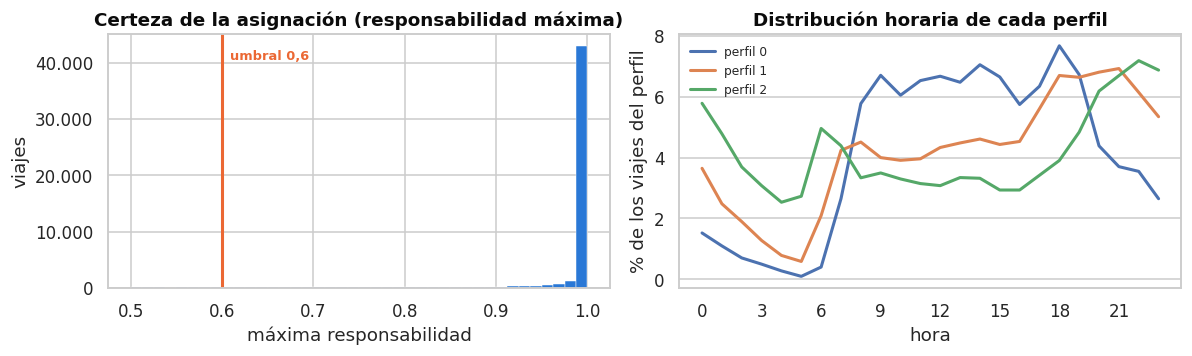

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(mixture_sample["confidence"], bins=40, color=BLUE, edgecolor="white", linewidth=0.3)
axes[0].axvline(0.6, color=ORANGE, lw=2)
axes[0].annotate("umbral 0,6", xy=(0.6, 0.9), xycoords=("data", "axes fraction"), xytext=(5, 0),
                 textcoords="offset points", color=ORANGE, fontsize=8.5, weight="bold")
axes[0].set_title("Certeza de la asignación (responsabilidad máxima)")
axes[0].set_xlabel("máxima responsabilidad")
axes[0].set_ylabel("viajes")
axes[0].yaxis.set_major_formatter(thousands)

for k in range(n_components):
    share = (mixture_sample.loc[mixture_sample["profile"] == k, "hour"]
             .value_counts(normalize=True).reindex(range(24), fill_value=0))
    axes[1].plot(share.index, 100 * share.to_numpy(), lw=2, label=f"perfil {k}")
axes[1].set_title("Distribución horaria de cada perfil")
axes[1].set_xlabel("hora")
axes[1].set_ylabel("% de los viajes del perfil")
axes[1].set_xticks(range(0, 24, 3))
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [39]:
# Sensibilidad a mínimos locales: se repite el ajuste con tres semillas por inicialización
# y con un K mayor al elegido, donde el problema de los óptimos locales sí aparece.
sensitivity_subset = X[np.random.default_rng(SEED).choice(len(X), 15_000, replace=False)]
sensitivity = pd.DataFrame([
    {"K": k, "inicialización": init, "semilla": seed,
     "log-verosimilitud": run["trace"][-1], "iteraciones": run["iterations"]}
    for k in (n_components, 6)
    for init in ("kmeans++", "random")
    for seed in (1, 2, 3)
    for run in [fit_gaussian_mixture(sensitivity_subset, k, init=init, seed=seed, max_iter=120)]
])
display(sensitivity.pivot_table(index=["K", "inicialización"],
                                values=["log-verosimilitud", "iteraciones"],
                                aggfunc={"log-verosimilitud": ["min", "max"],
                                         "iteraciones": "mean"}).round(3))

iteraciones log-verosimilitud       
                        mean               max    min
K inicialización                                     
3 kmeans++            57.000            -3.442 -3.442
  random              84.333            -3.442 -3.606
6 kmeans++            96.333            -2.468 -2.678
  random             120.000            -1.884 -2.318

### 6.4 · Sensibilidad al conjunto de variables

La velocidad es distancia dividida por duración, así que es una función determinista de las otras dos variables del espacio. Es una objeción legítima: la matriz de covarianza queda mal condicionada y por eso el EM regulariza con 1e-6. La pregunta es si quitarla mejora el modelo, y la respuesta se mide aquí en lugar de suponerse.


In [40]:
# --- 6.4 · Sensibilidad al conjunto de variables: el ajuste sin velocidad ---
# En teoria speed_kmh sobra: es funcion de las otras dos. Antes de quitarla medimos
# que pasa si lo hacemos.

def sigmas_originales(covariances, fitted_scaler):
    """Desviaciones por componente en unidades originales: diag de D Sigma D."""
    d = np.diag(fitted_scaler.scale_)
    return np.array([np.sqrt(np.diag(d @ c @ d)) for c in covariances])

FEATURES_SIN_VELOCIDAD = ["log_duration", "log_distance", "hour_sin", "hour_cos"]
scaler_sv = StandardScaler().fit(mixture_sample[FEATURES_SIN_VELOCIDAD])
X_sv = scaler_sv.transform(mixture_sample[FEATURES_SIN_VELOCIDAD])

bic_sv = pd.Series({k: GaussianMixture(k, covariance_type="full", random_state=SEED,
                                       n_init=3, max_iter=500).fit(X_sv).bic(X_sv)
                    for k in range(2, 9)})
k_sv = elbow_index(bic_sv)
em_sv = fit_gaussian_mixture(X_sv, k_sv, init="kmeans++")
conf_sv = em_sv["responsibilities"].max(axis=1)

# Diagnostico de colapso: si las componentes se pegan a horas concretas, la dispersion de
# los angulos horarios se hunde frente a la de duracion y distancia.
sigma_sv = pd.DataFrame(sigmas_originales(em_sv["covariances"], scaler_sv),
                        columns=FEATURES_SIN_VELOCIDAD)
sigma_full = pd.DataFrame(sigmas_originales(em_kmeanspp["covariances"], scaler), columns=FEATURES)

comparacion_variables = pd.DataFrame([
    {"modelo": "5 variables (reportado)", "K elegido": n_components,
     "log-verosimilitud": round(em_kmeanspp["trace"][-1], 4),
     "certeza media": round(mixture_sample["confidence"].mean(), 4),
     "% ambiguos (<0,6)": round(100 * (mixture_sample["confidence"] < 0.6).mean(), 2),
     "sigma mediana de la hora": round(float(
         sigma_full[["hour_sin", "hour_cos"]].mean(axis=1).median()), 4),
     "sigma mediana log-duracion": round(float(sigma_full["log_duration"].median()), 4)},
    {"modelo": "4 variables (sin velocidad)", "K elegido": int(k_sv),
     "log-verosimilitud": round(em_sv["trace"][-1], 4),
     "certeza media": round(float(conf_sv.mean()), 4),
     "% ambiguos (<0,6)": round(100 * float((conf_sv < 0.6).mean()), 2),
     "sigma mediana de la hora": round(float(
         sigma_sv[["hour_sin", "hour_cos"]].mean(axis=1).median()), 4),
     "sigma mediana log-duracion": round(float(sigma_sv["log_duration"].median()), 4)},
])
display(comparacion_variables)

sigma_sv.index.name = "componente"
display(sigma_sv.round(4))

,modelo,K elegido,log-verosimilitud,certeza media,"% ambiguos (<0,6)",sigma mediana de la hora,sigma mediana log-duracion
0,5 variables (reportado),3,-3.4590,0.9783,1.25,0.6846,0.7004
1,4 variables (sin velocidad),5,-3.2555,0.9999,0.00,0.2165,0.7281


,log_duration,log_distance,hour_sin,hour_cos
componente,,,,
0,0.7578,0.8760,0.2256,0.1738
1,0.7154,0.8288,0.0503,0.2766
2,0.7344,0.9185,0.2004,0.3475
3,0.7281,0.8264,0.3373,0.2558
4,0.6856,0.8520,0.3210,0.1120


**Lectura.** Sin velocidad las componentes se separan por la hora y no por el tipo de viaje: la dispersión de los ángulos horarios cae muy por debajo de la de duración y distancia, la certeza media se pega a 1 y no queda ningún viaje ambiguo. Eso no es buena separación sino colapso sobre los 24 valores discretos de la hora. Por eso se reporta el modelo de cinco variables y esta prueba queda documentada.


### Lectura

Las componentes se reordenan por velocidad media antes de perfilarlas, así que el perfil 0 es siempre el más lento sin importar cómo haya inicializado el EM. Los tres que aparecen no son los que se dibujarían a mano, pero se explican solos:

| Perfil | Peso | Duración | Distancia | Velocidad | Hora típica | % fin de semana | Lectura |
|---|---|---|---|---|---|---|---|
| 0 | 33,4 % | 12,0 min | 1,5 km | 8,0 km/h | 18:00 | 20,7 % | corto y atascado: Midtown en hora pico |
| 1 | 40,3 % | 10,0 min | 2,2 km | 13,5 km/h | 21:00 | 30,6 % | el viaje urbano corriente |
| 2 | 26,4 % | 11,8 min | 4,4 km | 22,4 km/h | 22:00 | 36,0 % | viaje largo y fluido: noche y aeropuertos |

El perfil 0 es el hallazgo: **tarda más que el perfil 1 recorriendo dos terceras partes de la distancia**. No es un viaje distinto, es el mismo viaje dentro del tráfico pesado. Y es el que menos aparece en fin de semana (20,7 % contra 36,0 % del perfil 2), lo que confirma que la congestión es un fenómeno de día laboral.

**Certeza de la pertenencia.** La responsabilidad máxima promedio es 0,978 y el 93 % de los viajes supera 0,9; solo el 1,25 % queda por debajo de 0,6. Las componentes están bien separadas en el espacio de velocidad y distancia.

**Inicialización.** En la corrida principal con K = 3 las dos inicializaciones llegan prácticamente al mismo óptimo (−3,45896 contra −3,45895). Pero la tabla de sensibilidad de la celda anterior matiza eso: con inicialización aleatoria y K = 3, una de las tres semillas quedó atrapada en −3,606 frente a −3,442 de las otras dos, mientras kmeans++ llegó al mismo valor en las tres. O sea que **el mínimo local también aparece con K = 3**; lo que pasa es que kmeans++ lo evitó, y eso es justamente el argumento a favor de esa inicialización. Con K = 6 el problema se vuelve evidente: los resultados cambian con la semilla en ambos casos. El EM garantiza que la log-verosimilitud suba, no que el punto de llegada sea el máximo global.

## 7. Decisiones para UrbanMove · Rol 4

**Responsabilidad:** justificar la selección de datos (sección 3), integrar los hallazgos de los tres bloques y traducirlos en recomendaciones cuantificadas.

Los cálculos de esta sección son los que sostienen cada recomendación: dimensionamiento por franja, costo de la congestión y desplazamiento de la demanda entre contextos.

> **Nota sobre la tabla de franjas.** La fila *Hora pico (18–19 h)* se solapa con *Tarde* y con *Noche*, así que la columna de porcentaje suma más de 100. Está puesta aparte a propósito, para poder dimensionar la hora pico sin sacarla de su franja.

In [41]:
# --- Concentración de la demanda por franja ---
# Compara el volumen y la concentración geográfica de cada franja horaria para
# dimensionar cuántos conductores mover y a dónde.
demand_by_window = pd.DataFrame([
    {
        "franja": label,
        "viajes": int(mask.sum()),
        "% del total": 100 * mask.mean(),
        "H(zona) [bits]": entropy(to_probabilities(
            trips.loc[mask, "pickup_neighborhood"].value_counts().to_numpy())),
        "% en top 10 zonas": 100 * trips.loc[mask, "pickup_neighborhood"]
                                 .value_counts(normalize=True).head(10).sum(),
        "velocidad mediana (km/h)": trips.loc[mask, "speed_kmh"].median(),
    }
    for label, mask in [
        ("Hora pico (18–19 h)", trips["hour"].isin([18, 19])),
        ("Mañana (6–11 h)", trips["time_of_day"] == "Morning"),
        ("Tarde (12–18 h)", trips["time_of_day"] == "Afternoon"),
        ("Noche (19–23 h)", trips["time_of_day"] == "Evening"),
        ("Madrugada (0–5 h)", trips["time_of_day"] == "Late Night"),
    ]
]).set_index("franja")
display(demand_by_window.round(2))

,viajes,% del total,H(zona) [bits],% en top 10 zonas,velocidad mediana (km/h)
franja,,,,,
Hora pico (18–19 h),177926,12.43,5.63,36.44,11.89
Mañana (6–11 h),351234,24.54,5.70,34.86,12.28
Tarde (12–18 h),510802,35.69,5.61,36.90,11.23
Noche (19–23 h),401929,28.08,5.66,35.63,13.97
Madrugada (0–5 h),167208,11.68,5.73,41.81,17.73


In [42]:
# --- Congestión ---
# El SLA de velocidad separa los viajes fluidos de los atascados; el costo se mide en
# minutos por kilómetro, que es la unidad que afecta la tarifa y la rotación de la flota.
trips["minutes_per_km"] = trips["trip_duration_minutes"] / trips["trip_distance"]
congested = trips["speed_kmh"] < SLA_SPEED_KMH

congestion_report = pd.DataFrame({
    "viajes": [int(congested.sum()), int((~congested).sum())],
    "% del total": [100 * congested.mean(), 100 * (~congested).mean()],
    "minutos por km (mediana)": [trips.loc[congested, "minutes_per_km"].median(),
                                 trips.loc[~congested, "minutes_per_km"].median()],
    "distancia mediana (km)": [trips.loc[congested, "trip_distance"].median(),
                               trips.loc[~congested, "trip_distance"].median()],
    "duración mediana (min)": [trips.loc[congested, "trip_duration_minutes"].median(),
                               trips.loc[~congested, "trip_duration_minutes"].median()],
}, index=[f"Bajo {SLA_SPEED_KMH:.0f} km/h", f"Sobre {SLA_SPEED_KMH:.0f} km/h"]).round(2)
display(congestion_report)

congestion_by_hour = (trips.assign(congested=congested)
                      .groupby(["hour", "is_weekend"], observed=True)["congested"].mean()
                      .unstack().rename(columns={False: "laboral", True: "fin de semana"}) * 100)
with pd.option_context("display.max_columns", None, "display.width", 200):
    display(congestion_by_hour.round(1).T)

peak_hour = congestion_by_hour["laboral"].idxmax()
peak_weekend = congestion_by_hour["fin de semana"].idxmax()
display(pd.DataFrame([
    {"contexto": "día laboral", "hora pico": f"{peak_hour} h",
     "% de viajes congestionados": round(congestion_by_hour.loc[peak_hour, "laboral"], 1)},
    {"contexto": "fin de semana", "hora pico": f"{peak_weekend} h",
     "% de viajes congestionados": round(congestion_by_hour.loc[peak_weekend, "fin de semana"], 1)},
]))

,viajes,% del total,minutos por km (mediana),distancia mediana (km),duración mediana (min)
Bajo 10 km/h,430488,30.08,7.80,1.43,12.22
Sobre 10 km/h,1000685,69.92,3.86,2.65,10.48


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
is_weekend,,,,,,,,,,,,,,,,,,,,,,,,
laboral,9.3,7.7,7.6,7.0,4.9,2.8,5.6,21.3,43.2,50.5,50.9,51.7,51.6,47.3,47.5,47.4,41.4,40.6,39.7,30.9,21.7,18.5,17.9,14.8
fin de semana,20.2,16.0,12.6,10.3,8.0,4.6,3.0,5.1,7.5,11.4,14.5,20.5,25.2,28.6,28.9,28.7,27.4,27.6,30.3,31.1,25.0,21.5,21.4,19.1


,contexto,hora pico,% de viajes congestionados
0,día laboral,11 h,51.7
1,fin de semana,19 h,31.1


In [43]:
# --- Desplazamiento de la demanda entre contextos ---
zone_shift = pd.DataFrame({
    "% laboral": 100 * p_weekday,
    "% fin de semana": 100 * p_weekend,
    "% festivo": 100 * p_holiday,
}, index=all_zones)
zone_shift["cambio fin de semana"] = zone_shift["% fin de semana"] - zone_shift["% laboral"]
zone_shift["cambio festivo"] = zone_shift["% festivo"] - zone_shift["% laboral"]
display(pd.concat([
    zone_shift.sort_values("cambio fin de semana", ascending=False).head(5),
    zone_shift.sort_values("cambio fin de semana").head(5),
]).round(3))

,% laboral,% fin de semana,% festivo,cambio fin de semana,cambio festivo
pickup_neighborhood,,,,,
East Village,2.650,4.696,3.539,2.046,0.889
Lower East Side,1.194,2.689,1.787,1.495,0.593
West Village,1.991,2.829,2.104,0.839,0.113
Greenwich Village South,1.294,1.954,1.433,0.660,0.139
Meatpacking/West Village West,1.180,1.659,1.239,0.479,0.059
Midtown Center,4.058,2.660,3.368,-1.398,-0.690
Upper East Side South,4.198,2.949,3.040,-1.248,-1.158
Midtown East,3.741,2.507,3.059,-1.234,-0.683
Upper East Side North,3.822,2.799,2.835,-1.023,-0.987


In [44]:
# --- Tabla de métricas por bloque ---
results_table = pd.DataFrame([
    ["Rol 1", "H(zona de recogida)", f"{zone_entropy:.2f} bits",
     f"{2 ** zone_entropy:.0f} zonas efectivas de {n_zones}"],
    ["Rol 1", "H(zona | hora)", f"{conditional_entropy:.2f} bits",
     "conocer la hora casi no reduce la incertidumbre"],
    ["Rol 1", "I(hora ; zona de recogida)", f"{mi_hour_zone:.4f} bits",
     f"{100 * mi_hour_zone / zone_entropy:.2f} % de H(zona)"],
    ["Rol 1", "I(zona recogida ; zona destino)",
     f"{mi_table.loc[mi_table.X == 'zona de recogida', 'I(X;Y) [bits]'].iat[0]:.4f} bits",
     f"{mi_table.loc[mi_table.X == 'zona de recogida', '% de H(Y) explicado'].iat[0]:.1f} % de H(destino)"],
    ["Rol 1", "KL(laboral || fin de semana)", f"{kl_table.loc[0, 'KL(p||q)']:.4f} bits",
     "distribuciones parecidas con zonas que se intercambian"],
    ["Rol 2", f"K-means k = {best_k}", f"silueta {kmeans_metrics.loc[best_k, 'silueta']:.3f}",
     " · ".join(kmeans_profile["barrio_dominante"].tolist())],
    ["Rol 2", f"DBSCAN eps = {eps:.0f} m", f"{n_dense} núcleos densos",
     f"{100 * (~is_signal).mean():.2f} % de ruido"],
    ["Rol 3", f"Mezcla gaussiana K = {n_components}",
     f"log-verosimilitud {em_kmeanspp['trace'][-1]:.3f}",
     f"{em_kmeanspp['iterations']} iteraciones hasta converger"],
    ["Rol 3", "Certeza media de pertenencia", f"{mixture_sample['confidence'].mean():.3f}",
     f"{(mixture_sample['confidence'] < 0.6).mean():.2%} de viajes ambiguos"],
    ["Rol 4", "Viajes bajo el umbral de congestión", f"{100 * congested.mean():.1f} %",
     f"{trips.loc[congested, 'minutes_per_km'].median():.1f} min/km contra "
     f"{trips.loc[~congested, 'minutes_per_km'].median():.1f} min/km"],
], columns=["Bloque", "Métrica", "Valor", "Lectura"])
display(results_table)

,Bloque,Métrica,Valor,Lectura
0,Rol 1,H(zona de recogida),5.72 bits,53 zonas efectivas de 237
1,Rol 1,H(zona | hora),5.64 bits,conocer la hora casi no reduce la incertidumbre
2,Rol 1,I(hora ; zona de recogida),0.0838 bits,1.46 % de H(zona)
3,Rol 1,I(zona recogida ; zona destino),0.4726 bits,7.7 % de H(destino)
4,Rol 1,KL(laboral || fin de semana),0.0553 bits,distribuciones parecidas con zonas que se inte...
5,Rol 2,K-means k = 4,silueta 0.496,Union Sq · JFK Airport · Upper East Side South...
6,Rol 2,DBSCAN eps = 393 m,7 núcleos densos,2.40 % de ruido
7,Rol 3,Mezcla gaussiana K = 3,log-verosimilitud -3.459,75 iteraciones hasta converger
8,Rol 3,Certeza media de pertenencia,0.978,1.25% de viajes ambiguos
9,Rol 4,Viajes bajo el umbral de congestión,30.1 %,7.8 min/km contra 3.9 min/km


### Tres recomendaciones

**1. Posicionar por zona, dimensionar por hora.**
La información mutua entre hora y zona de recogida es de 0,0838 bits: el reloj explica el 1,46 % de la incertidumbre sobre dónde saldrá el próximo viaje, y el 1,83 % de la del destino. En cambio, 10 zonas concentran entre el 35 % y el 42 % de la demanda en cualquier franja. La recomendación es fijar una base estable de conductores en esas 10 zonas y mover con la hora **el volumen**: las franjas duran distinto, así que la comparación se hace **por viajes por hora**: la madrugada (0–5 h) mueve 27.868 viajes por hora contra 72.972 de la tarde (12–18 h), es decir el 38 % del ritmo, no un tercio. La franja más intensa por hora es en realidad la noche (19–23 h) con 80.386. Si se dimensiona por la hora de máxima demanda la brecha es mayor: 89.076 viajes a las 18 h contra 14.612 a las 5 a.m., un 16 %. La excepción es la madrugada, donde la zona dominante cambia a East Village y sus 10 zonas concentran el 41,8 %: ahí sí conviene una reasignación explícita.

**2. Ponderar el tiempo en la tarifa de las horas congestionadas.**
El 30,1 % de los viajes va por debajo de 10 km/h y gasta **7,80 minutos por kilómetro contra 3,86 del resto: 2,02 veces, aproximadamente el doble**. En día laboral, entre las 8 a.m. y las 4 p.m. más del 40 % de los viajes cae en esa condición, con un pico de 51,7 % a las 11 h, mientras el fin de semana no pasa del 31,1 %. El perfil 0 de la mezcla, que es el 33,4 % de los viajes, es justamente ese. Una tarifa que solo cobre distancia castiga al conductor en las horas de mayor demanda; hay que ponderar el componente de tiempo en la franja laboral de 8 a 16 h.

**3. Reasignar el fin de semana y atender el borde bajo demanda.**
La KL entre laboral y fin de semana es baja (0,055 bits), pero el detalle por zona muestra el movimiento: East Village +2,05 puntos porcentuales, Lower East Side +1,49, West Village +0,84, mientras Midtown Center cae 1,40 y Upper East Side South 1,25. Midtown Center pasa de 4,06 % a 2,66 % de los viajes, una **caída relativa del 34 %**, y de ahí sale el orden de magnitud de la reasignación: mover el fin de semana alrededor de un tercio de la flota de Midtown hacia East Village, Lower East Side y West Village. Es una propuesta inicial derivada de esa caída, no un óptimo calculado: para fijarla haría falta un modelo de asignación con costos de desplazamiento. En paralelo, el 2,40 % de viajes que DBSCAN marca como ruido (43 % Queens, 38 % Brooklyn, 17 % Manhattan) no debe tener flota estacionada: se atiende bajo demanda y se excluye de la promesa de tiempo de espera.

### Limitaciones y siguientes pasos

- Los datos cubren **enero a junio de 2016** y solo taxi amarillo: no incluyen el invierno completo ni los servicios por aplicación, que son el competidor real de UrbanMove.
- No hay **tarifa, clima ni eventos**. La recomendación de precio se sostiene en minutos por kilómetro, no en ingresos observados.
- La distancia es **en línea recta**: subestima el recorrido real, sobre todo en Manhattan, donde la retícula obliga a rodear. El efecto es mayor en los viajes cortos, que son la mayoría.
- Clustering y mezcla usan una **muestra de 50.000 viajes**; entropías, información mutua y KL usan la base de trabajo completa (1.431.173 viajes).
- Los festivos son solo el 1,9 % de los viajes: las conclusiones sobre ellos tienen menos respaldo que las demás.
- **La mezcla puede degenerar y el BIC lo refleja.** `hour_sin` y `hour_cos` solo toman 24 valores distintos, así que una componente puede colapsar sobre una sola hora y disparar la verosimilitud sin describir nada nuevo. Eso explica tres cosas que se ven en las salidas: que el BIC no se estabilice dentro del rango probado y su menor valor quede en el borde (K = 8), que la mejora suba de K = 3 a K = 4 en vez de caer, y que la corrida aleatoria con K = 6 llegue a −1,884 sin converger en 120 iteraciones. A eso se suma que `speed_kmh` es casi una función de duración y distancia, de modo que hay información repetida entre las cinco variables. El siguiente paso natural es reajustar la mezcla sin las variables de hora y comparar si los tres perfiles sobreviven.
- El **eps de DBSCAN** sale del codo de la curva de distancia al vecino 50. Es una regla reproducible, pero sigue siendo una elección: con el percentil 95 el eps baja a 274 m y el ruido sube al 4,19 % con 5 núcleos, ejecutado en la celda de reglas alternativas. La conclusión cualitativa aguanta las dos reglas: hay una minoría dispersa en Queens y Brooklyn que no justifica flota fija.
- Siguiente paso: repetir el análisis de entropía sobre una **rejilla espacial propia** en vez de los barrios oficiales (237 zonas de tamaño muy desigual) y cruzar con clima para ver cuánta incertidumbre queda explicada.

## Equipo y entregables

| Integrante | Código | Rol |
|---|---|---|
| Ricardo Borja | 0000333542 | Rol 1 · Analista de Incertidumbre e Información |
| Gabriel Murillo | 0000285035 | Rol 2 · Arquitecto de Segmentación por Partición |
| Samuel Robayo | 0000329495 | Rol 3 · Modelador de Mezclas y Variables Latentes |
| Maria Andrea Torres | 0000334682 | Rol 4 · Estratega de Negocio y Selección de Datos |